# Movie Recommendation Engine: Ranking, Cold Start and Explainable Recommendations

## Business problem
A streaming platform has about 3,700 movies and thousands of users. Users who can't find something to watch leave.
Goal: for each user, produce a ranked top-10 list of movies they have not seen and are likely to rate 4 or higher.

## Success criteria
- **Relevance:** Precision@10, Recall@10, NDCG@10 against a time-aware hold-out
- **Discovery:** catalogue coverage, intra-list diversity, novelty
- **Trust:** every recommendation comes with a plain-language reason
- **Robustness:** explicit evaluation of new users and new movies

## Why not RMSE?
Predicting a 3.8 versus a 4.1 doesn't matter to a user. What matters is whether the right movies appear at the top of the list.
Rating-prediction error is reported only as a secondary diagnostic.

In [1]:
import random
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42                      # one seed everywhere, so reruns match
random.seed(SEED); np.random.seed(SEED)

DATA_DIR = Path("../data/raw/ml-1m")   # needs ratings.dat, movies.dat, users.dat (original names)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
AGE_LABELS = {1: "Under 18", 18: "18-24", 25: "25-34", 35: "35-44", 45: "45-49", 50: "50-55", 56: "56+"}
OCC_LABELS = {0: "other", 1: "academic/educator", 2: "artist", 3: "clerical/admin", 4: "college/grad student",
              5: "customer service", 6: "doctor/health care", 7: "executive/managerial", 8: "farmer",
              9: "homemaker", 10: "K-12 student", 11: "lawyer", 12: "programmer", 13: "retired",
              14: "sales/marketing", 15: "scientist", 16: "self-employed", 17: "technician/engineer",
              18: "tradesman/craftsman", 19: "unemployed", 20: "writer"}

def load_ml1m(data_dir: Path):
    """Read the three '::'-separated MovieLens-1M files into tidy DataFrames."""
    kw = dict(sep="::", engine="python")            # multi-character separator needs the python engine
    ratings = pd.read_csv(data_dir / "ratings.dat", names=["user_id", "movie_id", "rating", "timestamp"], **kw)
    movies = pd.read_csv(data_dir / "movies.dat", names=["movie_id", "title", "genres"],
                         encoding="latin-1", **kw)   # titles contain non-UTF8 characters
    users = pd.read_csv(data_dir / "users.dat",
                        names=["user_id", "gender", "age_code", "occupation_code", "zip"], **kw)
    ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
    movies["year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$")[0].astype("Int64")
    movies["genre_list"] = movies["genres"].str.split("|")
    users["age"] = users["age_code"].map(AGE_LABELS)
    users["occupation"] = users["occupation_code"].map(OCC_LABELS)
    return ratings, movies, users

ratings, movies, users = load_ml1m(DATA_DIR)
print(ratings.shape, movies.shape, users.shape)

(1000209, 5) (3883, 5) (6040, 7)


In [3]:
# If any assert fails, the data is not what the rest of the notebook assumes.
assert len(ratings) == 1_000_209 and ratings.user_id.nunique() == 6_040
assert len(movies) == 3_883 and len(users) == 6_040
assert ratings[["user_id", "movie_id", "rating", "timestamp"]].notna().all().all()
assert not ratings.duplicated(["user_id", "movie_id"]).any()      # one rating per user-movie pair
assert ratings.rating.between(1, 5).all()
assert ratings.movie_id.isin(movies.movie_id).all() and ratings.user_id.isin(users.user_id).all()
assert users.occupation.notna().all() and users.age.notna().all() and movies.year.notna().all()

n_u, n_i, n = ratings.user_id.nunique(), ratings.movie_id.nunique(), len(ratings)
print(f"users={n_u:,}  rated movies={n_i:,}  (catalogue={len(movies):,}, never rated={len(movies)-n_i})")
print(f"sparsity = {1 - n/(n_u*n_i):.2%}")
print(f"period: {ratings.datetime.min():%Y-%m-%d} -> {ratings.datetime.max():%Y-%m-%d}")


users=6,040  rated movies=3,706  (catalogue=3,883, never rated=177)
sparsity = 95.53%
period: 2000-04-25 -> 2003-02-28


In [4]:
by_user = ratings.sort_values(["user_id", "timestamp"]).groupby("user_id")
span_days = (by_user.timestamp.max() - by_user.timestamp.min()) / 86_400
share_tied = by_user.timestamp.apply(lambda s: s.duplicated(keep=False).mean())
last_two_tied = by_user.timestamp.apply(lambda s: s.iloc[-1] == s.iloc[-2])   # every user has >= 20 ratings

print(pd.Series({
    "median user activity span (minutes)": span_days.median() * 1440,
    "users who rated everything within 1 day": (span_days < 1).mean(),
    "users active for more than 30 days": (span_days > 30).mean(),
    "avg share of a user's ratings tied to another rating's second": share_tied.mean(),
    "users whose LAST TWO ratings share a timestamp": last_two_tied.mean(),
}).to_string())

median user activity span (minutes)                             67.808
users who rated everything within 1 day                          0.629
users active for more than 30 days                               0.238
avg share of a user's ratings tied to another rating's second    0.766
users whose LAST TWO ratings share a timestamp                   0.421


In [5]:
item_counts = ratings.movie_id.value_counts()
print(f"top 10% of movies receive {item_counts.head(int(0.10*len(item_counts))).sum()/n:.1%} of all ratings")
print(f"movies with <5 ratings: {(item_counts<5).sum()}  | <20 ratings: {(item_counts<20).sum()}")

top 10% of movies receive 44.4% of all ratings
movies with <5 ratings: 290  | <20 ratings: 663


In [6]:
cut = ratings.timestamp.quantile(0.80)
train, test = ratings[ratings.timestamp <= cut], ratings[ratings.timestamp > cut]
print(f"cut date = {pd.to_datetime(cut, unit='s'):%Y-%m-%d}")
print(f"test ratings from users with NO training history: {(~test.user_id.isin(train.user_id)).mean():.1%}")

cut date = 2000-12-02
test ratings from users with NO training history: 47.7%


## What the data tells us about how to evaluate

### The data is clean but very sparse
All 1,000,209 ratings pass the integrity checks: no missing values, no duplicate user-movie pairs, and every user and movie ID matches its lookup table. The 6,040 users rated 3,706 of the 3,883 movies in the catalogue (177 were never rated), so 95.53% of all possible user-movie pairs are empty. A model has to predict taste from very little information per user.

### Ratings are made in short sessions, not spread over time
- The median user's whole rating history spans about **68 minutes**.
- **62.9%** of users rated everything within a single day, and only **23.8%** were active for more than 30 days.
- On average **76.6%** of a user's ratings share a timestamp (to the second) with another of their ratings.
- **42.1%** of users have their last two ratings at the same second, so "the last movie a user rated" is often arbitrary.

These users mostly rated a batch of movies in one sitting, probably when they joined, rather than rating over months.

### What this means for the evaluation design
1. **A global time cut does not work here.** Cutting the data at 2000-12-02 (80% of ratings before, 20% after) leaves **47.7%** of test ratings coming from users with no training history. That would test how we treat brand-new users, not how well we predict a known user's future taste. It acts as a user-level split, not a forecast.
2. **We use a per-user chronological hold-out instead.** For each user, the oldest ratings are used for training and the newest for testing. This keeps the "past predicts future" logic for every user and means every test user has history.
3. **Timestamp ties are broken by the original file order.** Because the end of a user's history is often tied, we measure in the split section how much this choice matters, instead of assuming it doesn't.
4. **Cold-start users are tested separately.** Every user here has at least 20 ratings, so we simulate new users by revealing only their first few ratings.

### Limitation we accept
In a per-user split, training still contains other users' later ratings. This is standard practice for offline recommender evaluation, but it is slightly more optimistic than a true live deployment, and we state it again in the limitations section.

## 2. Exploratory analysis and evaluation split
Each chart answers one question, and each answer drives a modelling decision.


In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlepad": 10,
    "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})

def only_grid(ax, axis):
    """Keep a hairline grid on one axis only (less ink, same readability)."""
    ax.grid(False)
    ax.grid(axis=axis)

POS_THRESHOLD = 4                                    # rating >= 4 means "the user liked it" = relevant item
ratings["liked"] = ratings.rating >= POS_THRESHOLD   # reused by every later step
n = len(ratings)

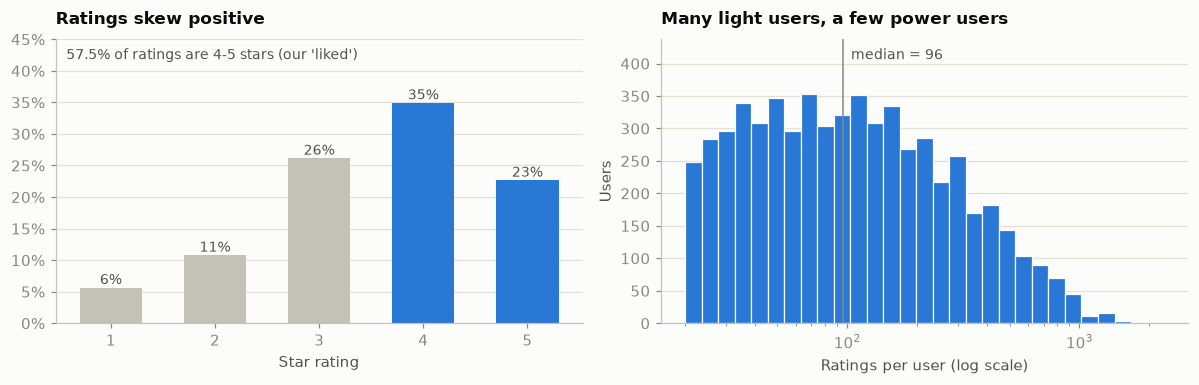

liked share = 57.5% | median ratings/user = 96 | top 1% of users supply 6.9% of all ratings


In [8]:
rating_share = ratings.rating.value_counts(normalize=True).sort_index()
per_user = ratings.groupby("user_id").size()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))

a1.bar(rating_share.index, rating_share.values, width=0.6,
       color=[GRAY if r < POS_THRESHOLD else BLUE for r in rating_share.index])
for r, v in rating_share.items():
    a1.text(r, v + 0.006, f"{v:.0%}", ha="center", color=INK2, fontsize=9)
a1.set(title="Ratings skew positive", xlabel="Star rating", ylim=(0, 0.45))
a1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
a1.text(0.02, 0.93, f"{ratings.liked.mean():.1%} of ratings are 4-5 stars (our 'liked')",
        transform=a1.transAxes, color=INK2, fontsize=9)
only_grid(a1, "y")

bins = np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 30)
a2.hist(per_user, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
a2.set_xscale("log")
a2.set_ylim(0, a2.get_ylim()[1] * 1.18)                      # head-room so the label sits above the bars
a2.axvline(per_user.median(), color=MUTED, lw=1)
a2.text(per_user.median() * 1.08, a2.get_ylim()[1] * 0.93, f"median = {per_user.median():.0f}", color=INK2, fontsize=9)
a2.set(title="Many light users, a few power users", xlabel="Ratings per user (log scale)", ylabel="Users")
only_grid(a2, "y")
plt.tight_layout(); plt.show()

top1 = per_user.sort_values(ascending=False).head(int(0.01 * len(per_user))).sum() / n
print(f"liked share = {ratings.liked.mean():.1%} | median ratings/user = {per_user.median():.0f} | "
      f"top 1% of users supply {top1:.1%} of all ratings")

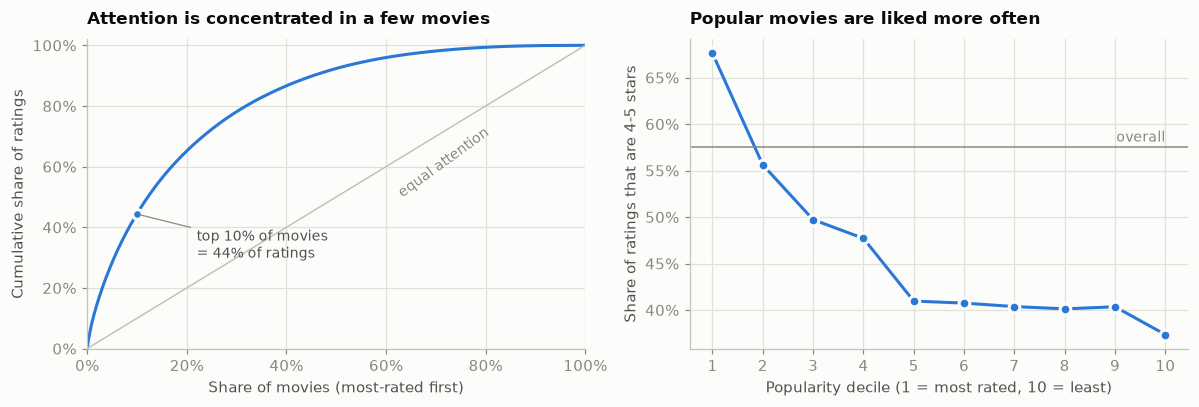

most-rated decile: 67.6% liked | least-rated decile: 37.4% liked


In [9]:
item_counts = ratings.movie_id.value_counts()                # ratings per movie, sorted high -> low
cum_share = item_counts.cumsum().to_numpy() / n              # cumulative share of ratings
movie_share = np.arange(1, len(item_counts) + 1) / len(item_counts)

# rank movies by popularity and cut into 10 equal-sized groups (1 = most rated)
rank = item_counts.rank(method="first", ascending=False)
decile = pd.qcut(rank, 10, labels=range(1, 11)).rename("pop_decile")
liked_by_decile = (ratings.merge(decile, left_on="movie_id", right_index=True)
                   .groupby("pop_decile", observed=True).liked.mean())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(movie_share, cum_share, color=BLUE, lw=2)
a1.plot([0, 1], [0, 1], color=AXIS, lw=1)                    # what "perfectly equal attention" would look like
i10 = int(0.10 * len(item_counts))
a1.scatter([movie_share[i10 - 1]], [cum_share[i10 - 1]], s=40, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
a1.annotate(f"top 10% of movies\n= {cum_share[i10 - 1]:.0%} of ratings", (movie_share[i10 - 1], cum_share[i10 - 1]),
            xytext=(0.22, 0.30), color=INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
a1.text(0.62, 0.50, "equal attention", color=MUTED, fontsize=9, rotation=36)
a1.set(title="Attention is concentrated in a few movies", xlabel="Share of movies (most-rated first)",
       ylabel="Cumulative share of ratings", xlim=(0, 1), ylim=(0, 1.02))
a1.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); a1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

a2.plot(liked_by_decile.index.astype(int), liked_by_decile.values, color=BLUE, lw=2, marker="o", ms=7,
        markeredgecolor=SURFACE, markeredgewidth=2)
a2.axhline(ratings.liked.mean(), color=MUTED, lw=1)
a2.text(10, ratings.liked.mean() + 0.006, "overall", color=MUTED, fontsize=9, ha="right")
a2.set(title="Popular movies are liked more often", xlabel="Popularity decile (1 = most rated, 10 = least)",
       ylabel="Share of ratings that are 4-5 stars", xticks=range(1, 11))
a2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
plt.tight_layout(); plt.show()

print(f"most-rated decile: {liked_by_decile.iloc[0]:.1%} liked | least-rated decile: {liked_by_decile.iloc[-1]:.1%} liked")

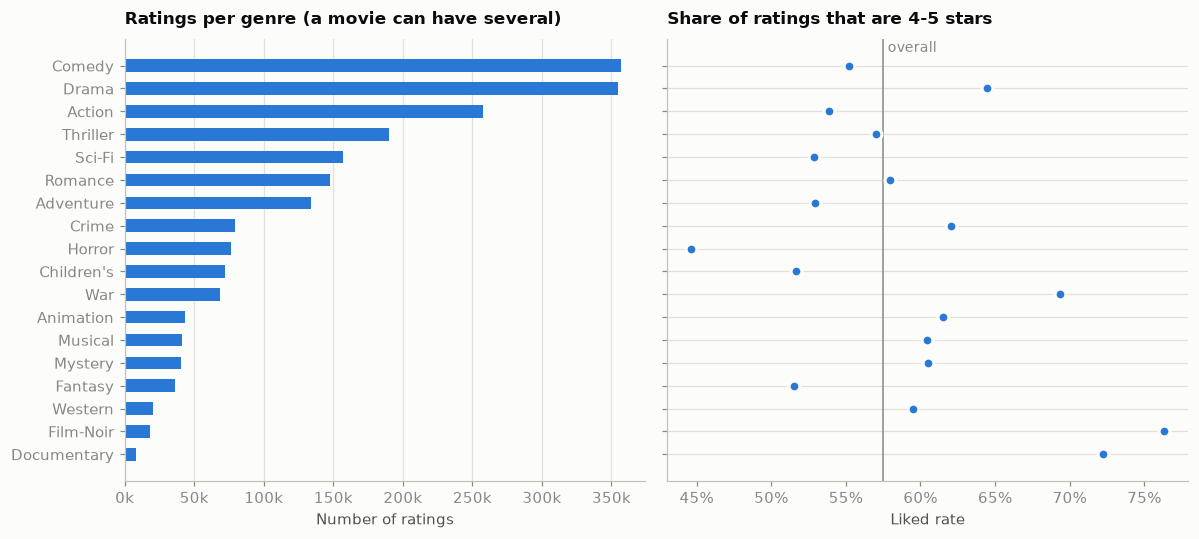

least liked: Horror 45%, Fantasy 52%, Children's 52%
most liked : Film-Noir 76%, Documentary 72%, War 69%
most rated : Comedy (356,580), Drama (354,529), Action (257,457)


In [10]:
rg = ratings[["movie_id", "liked"]].merge(movies[["movie_id", "genre_list"]], on="movie_id").explode("genre_list")
genre = (rg.groupby("genre_list").agg(n_ratings=("liked", "size"), liked_rate=("liked", "mean"))
         .sort_values("n_ratings"))                          # ascending, so the biggest genre ends up on top
y = np.arange(len(genre))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
a1.barh(y, genre.n_ratings, height=0.55, color=BLUE)
a1.set_yticks(y, genre.index)
a1.set(title="Ratings per genre (a movie can have several)", xlabel="Number of ratings")
a1.xaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
only_grid(a1, "x")

a2.scatter(genre.liked_rate, y, s=50, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
a2.axvline(ratings.liked.mean(), color=MUTED, lw=1)
a2.text(ratings.liked.mean() + 0.003, len(genre) - 0.4, "overall", color=MUTED, fontsize=9)
a2.set(title="Share of ratings that are 4-5 stars", xlabel="Liked rate")
a2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
only_grid(a2, "y")
plt.tight_layout(); plt.show()

g_sorted = genre.sort_values("liked_rate")
print("least liked:", ", ".join(f"{k} {v:.0%}" for k, v in g_sorted.liked_rate.head(3).items()))
print("most liked :", ", ".join(f"{k} {v:.0%}" for k, v in g_sorted.liked_rate.tail(3)[::-1].items()))
print("most rated :", ", ".join(f"{k} ({int(v):,})" for k, v in genre.n_ratings.tail(3)[::-1].items()))

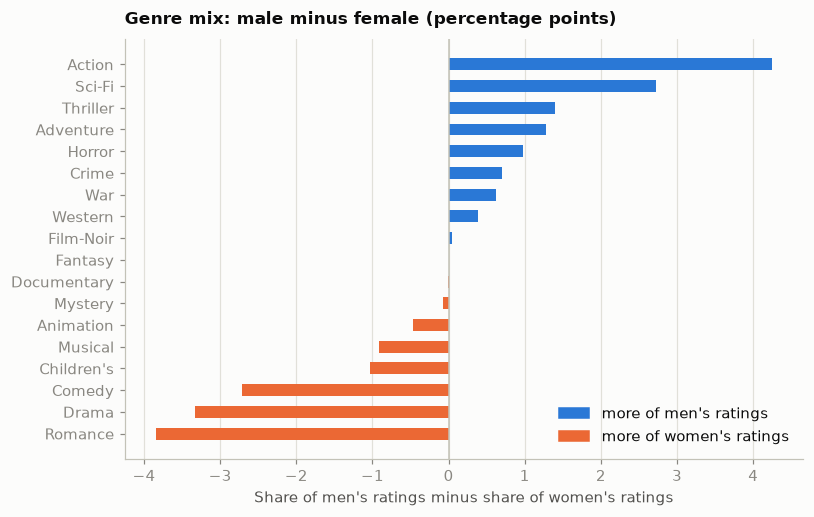

{'M': 0.717, 'F': 0.283} | ratings share: {'M': 0.754, 'F': 0.246}
largest gap: 4.2 percentage points (Action)


In [11]:
ug = (ratings[["user_id", "movie_id"]].merge(users[["user_id", "gender"]], on="user_id")
      .merge(movies[["movie_id", "genre_list"]], on="movie_id").explode("genre_list"))
mix = ug.groupby(["gender", "genre_list"]).size().unstack(0)
mix = mix / mix.sum()                                        # each gender's genre mix sums to 100%
gap = ((mix["M"] - mix["F"]) * 100).sort_values()            # percentage points

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh(np.arange(len(gap)), gap.values, height=0.55, color=[BLUE if v > 0 else ORANGE for v in gap.values])
ax.set_yticks(np.arange(len(gap)), gap.index)
ax.axvline(0, color=AXIS, lw=1)
ax.set(title="Genre mix: male minus female (percentage points)", xlabel="Share of men's ratings minus share of women's ratings")
ax.legend(handles=[Patch(color=BLUE, label="more of men's ratings"), Patch(color=ORANGE, label="more of women's ratings")],
          loc="lower right")
only_grid(ax, "x")
plt.tight_layout(); plt.show()

print(users.gender.value_counts(normalize=True).round(3).to_dict(), "| ratings share:",
      ratings.merge(users[["user_id", "gender"]], on="user_id").gender.value_counts(normalize=True).round(3).to_dict())
print(f"largest gap: {gap.abs().max():.1f} percentage points ({gap.abs().idxmax()})")

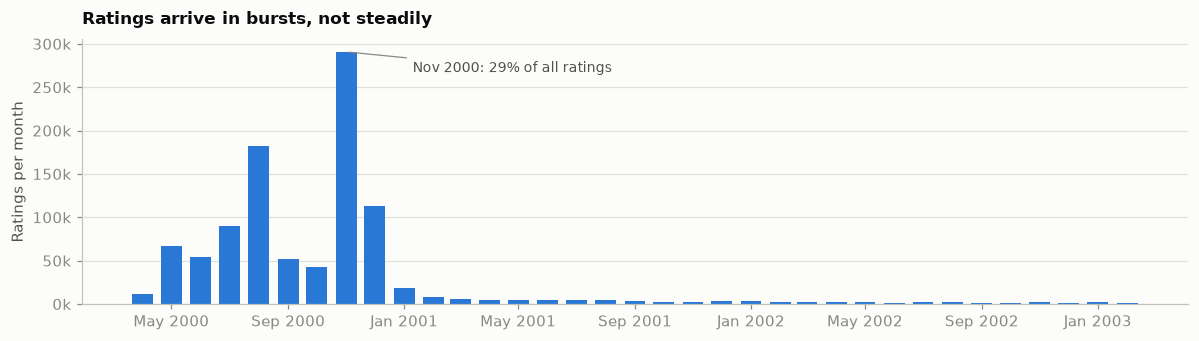

busiest 3 months hold 58.6% of all ratings


In [12]:
monthly = ratings.set_index("datetime").resample("MS").size()
peak = monthly.idxmax()

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(monthly.index, monthly.values, width=22, color=BLUE)
ax.annotate(f"{peak:%b %Y}: {monthly.max() / n:.0%} of all ratings", (peak, monthly.max()),
            xytext=(peak + pd.Timedelta(days=70), monthly.max() * 0.92), color=INK2, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set(title="Ratings arrive in bursts, not steadily", ylabel="Ratings per month")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
only_grid(ax, "y")
plt.tight_layout(); plt.show()

print(f"busiest 3 months hold {monthly.nlargest(3).sum() / n:.1%} of all ratings")

In [13]:
def chronological_split(df, val_frac=0.10, test_frac=0.20, tie_break="file", seed=SEED):
    """Per-user chronological split: each user's OLDEST ratings -> train, next block -> val, NEWEST -> test.

    tie_break="file"  : ratings sharing a timestamp keep their order in ratings.dat (the default)
    tie_break="random": ties are ordered randomly (used only to measure how much the tie choice matters)
    """
    assert tie_break in ("file", "random")
    work = df[["user_id", "movie_id", "rating", "timestamp"]].copy()
    if tie_break == "random":
        work = work.sample(frac=1.0, random_state=seed)      # shuffle first, so ties end up in random order
    work["_order"] = np.arange(len(work))                    # explicit final tie-breaker -> fully deterministic
    work = work.sort_values(["user_id", "timestamp", "_order"]).drop(columns="_order")

    g = work.groupby("user_id")
    pos = g.cumcount().to_numpy()                            # 0 = this user's oldest rating
    size = g["movie_id"].transform("size").to_numpy()        # number of ratings of this user
    n_test = np.maximum(1, (test_frac * size + 0.5).astype(int))   # round half up, at least 1
    n_val = np.maximum(1, (val_frac * size + 0.5).astype(int))
    work["split"] = np.select([pos >= size - n_test, pos >= size - n_test - n_val], ["test", "val"], default="train")
    return work

split_df = chronological_split(ratings)
train, val, test = (split_df[split_df.split == s] for s in ("train", "val", "test"))
print({s: f"{len(d):,} ({len(d) / n:.1%})" for s, d in zip(("train", "val", "test"), (train, val, test))})

{'train': '699,920 (70.0%)', 'val': '100,273 (10.0%)', 'test': '200,016 (20.0%)'}


In [14]:
assert len(train) + len(val) + len(test) == n                       # nothing lost, nothing duplicated
assert not split_df.duplicated(["user_id", "movie_id"]).any()       # a (user, movie) pair lives in exactly one split
assert split_df.groupby("user_id").split.nunique().eq(3).all()      # every user is in train, val AND test

b = split_df.groupby(["user_id", "split"]).timestamp.agg(["min", "max"]).unstack("split")
assert (b[("max", "train")] <= b[("min", "val")]).all()             # train is never newer than val
assert (b[("max", "val")] <= b[("min", "test")]).all()              # val is never newer than test
print("leakage checks passed: complete, disjoint, every user in all splits, chronological per user")

tied = (b[("max", "val")] == b[("min", "test")])
print(f"users whose val/test boundary falls inside a timestamp tie: {tied.mean():.1%}")

leakage checks passed: complete, disjoint, every user in all splits, chronological per user
users whose val/test boundary falls inside a timestamp tie: 49.1%


In [15]:
split_rand = chronological_split(ratings, tie_break="random")
in_test_file = split_df.split.eq("test")
in_test_rand = split_rand.split.reindex(split_df.index).eq("test")
jaccard = (in_test_file & in_test_rand).sum() / (in_test_file | in_test_rand).sum()
print(f"test-set overlap between file-order and random tie-break (Jaccard): {jaccard:.1%}")
print(f"ratings that land in a different split: {(split_df.split != split_rand.split.reindex(split_df.index)).mean():.1%}")

test-set overlap between file-order and random tie-break (Jaccard): 97.5%
ratings that land in a different split: 1.0%


In [16]:
test_liked = test[test.rating >= POS_THRESHOLD].groupby("user_id").size()
print(f"users with at least one liked test movie: {len(test_liked):,} / {n_u:,} (only these can be scored)")
print(f"liked test movies per user: median {test_liked.median():.0f}, max {test_liked.max()}")
print(f"test ratings on movies never seen in train: {(~test.movie_id.isin(train.movie_id)).mean():.2%}")
print(f"val ratings on movies never seen in train : {(~val.movie_id.isin(train.movie_id)).mean():.2%}")


users with at least one liked test movie: 5,966 / 6,040 (only these can be scored)
liked test movies per user: median 11, max 229
test ratings on movies never seen in train: 0.03%
val ratings on movies never seen in train : 0.02%


## Split verification: what the checks show

### The split is clean
The training, validation and test sets (about 70% / 10% / 20% of each user's ratings, oldest to newest) pass every leakage check:
- No rating is lost or duplicated, and no user-movie pair appears in more than one split.
- Every user appears in train, validation and test.
- For every user, training ratings are never newer than validation ratings, and validation ratings are never newer than test ratings.

So no model can learn from a user's future ratings to predict their past.

### Timestamp ties matter less than they first appear
**49.1%** of users have the boundary between validation and test falling inside a timestamp tie, so for these users "which ratings are the newest" depends on how ties are ordered. To test whether this affects the evaluation, we re-split with a random tie-break:
- The two test sets overlap by **97.5%** (Jaccard).
- Only **1.0%** of all ratings land in a different split.

The tie-break choice is therefore a real ambiguity but a very small one. We keep the original file order, and we do not expect it to change which model wins.

### What we can evaluate
- **5,966 of 6,040 users** have at least one liked test movie (rating 4 or higher), so only these users can be scored on test. The other 74 are left out of the metrics because there is nothing to find for them.
- The median scorable user has **11** liked test movies, and the maximum is **229**. Recall@10 is therefore capped for heavy users: with 229 liked movies, even a perfect top-10 list can find at most 10 of them.

### The split cannot test new movies
Only **0.03%** of test ratings (and 0.02% of validation ratings) are on movies that never appear in training. In this per-user chronological split, almost every test movie has already been seen by the model through other users' ratings.

This means we cannot measure how the system handles brand-new movies from this split. Cold-start movies must be tested separately, by holding out a set of movies and scoring them using content information only. The same applies to new users, who are simulated by revealing only the first few ratings of existing users.

### Limitation
Training still contains other users' later ratings. This is standard for offline recommender evaluation, but it is slightly more optimistic than a live deployment.

## 3. Evaluation framework

**Protocol.** A model scores every movie for every user. We remove movies the user has already seen, keep the top 10, and
count how many are movies the user later rated 4 or higher. Validation excludes training movies only; the final test excludes
training and validation movies. Metrics are averaged per user, so heavy raters do not dominate.

**Metrics.** Precision, Recall, Hit rate and NDCG@10 measure relevance and ranking quality (NDCG is the headline metric).
Coverage, diversity and novelty measure whether the system helps users discover varied movies, not just blockbusters.

**Why test the metrics?** Every later conclusion depends on these functions, so we check them on small cases computed by hand,
then bound them with a random recommender (floor) and an oracle (ceiling).

In [17]:
K = 10                                                        # primary list length: "top-10"

user_ids = np.sort(ratings.user_id.unique())
item_ids = np.sort(ratings.movie_id.unique())                 # the 3,706 movies that have at least one rating
n_users, n_items = len(user_ids), len(item_ids)
u_pos = pd.Series(np.arange(n_users), index=user_ids)         # user_id  -> matrix row
i_pos = pd.Series(np.arange(n_items), index=item_ids)         # movie_id -> matrix column

def to_mask(df):
    """Boolean users x items matrix: True where (user, movie) appears in df."""
    m = np.zeros((n_users, n_items), dtype=bool)
    m[u_pos.loc[df.user_id.to_numpy()].to_numpy(), i_pos.loc[df.movie_id.to_numpy()].to_numpy()] = True
    return m

seen_train, seen_val = to_mask(train), to_mask(val)
rel_val = to_mask(val[val.rating >= POS_THRESHOLD])           # relevant = held-out AND liked
rel_test = to_mask(test[test.rating >= POS_THRESHOLD])

# For each split: which movies may NOT be recommended (already seen) and which count as hits
PROTOCOL = {
    "val":  {"exclude": seen_train,              "relevant": rel_val},
    "test": {"exclude": seen_train | seen_val,   "relevant": rel_test},
}
EVAL_ROWS = {s: np.flatnonzero(p["relevant"].any(axis=1)) for s, p in PROTOCOL.items()}   # users with >= 1 relevant item
print({s: f"{len(r):,} users can be scored" for s, r in EVAL_ROWS.items()})

# side information used by the beyond-accuracy metrics
gx = movies[["movie_id", "genre_list"]].explode("genre_list", ignore_index=True)   # one row per (movie, genre)
genre_mat = pd.crosstab(gx.movie_id, gx.genre_list).reindex(item_ids).fillna(0).to_numpy(dtype=np.float32)   # items x 18
item_pop_prob = np.maximum(seen_train.sum(axis=0), 1) / n_users                                              # share of users who rated each movie

{'val': '5,819 users can be scored', 'test': '5,966 users can be scored'}


In [18]:
def ranking_metrics(recs, rel, k):
    """Per-user ranking metrics for a (users x >=k) matrix of recommended item columns.
    rel is the matching (users x items) boolean matrix of relevant items."""
    recs = recs[:, :k]
    hits = np.take_along_axis(rel, recs, axis=1)                    # (users, k) True where the slot is a hit
    n_rel = rel.sum(axis=1)
    discounts = 1.0 / np.log2(np.arange(2, k + 2))                  # rank 1 -> 1.0, rank 2 -> 0.63, rank 3 -> 0.5 ...
    dcg = (hits * discounts).sum(axis=1)
    idcg = np.cumsum(discounts)[np.minimum(n_rel, k) - 1]           # best possible DCG for this user
    return {"precision": hits.sum(axis=1) / k,
            "recall": hits.sum(axis=1) / n_rel,
            "hit_rate": hits.any(axis=1).astype(float),
            "ndcg": dcg / idcg}

def catalogue_coverage(recs, n_items):
    """Share of the catalogue that appears in at least one user's list."""
    return len(np.unique(recs)) / n_items

def novelty(recs, pop_prob):
    """Mean self-information (bits) of recommended items: higher = rarer, less obvious movies."""
    return float((-np.log2(pop_prob[recs])).mean())

def intra_list_diversity(recs, genres):
    """Mean pairwise (1 - Jaccard similarity of genre sets) inside each list, averaged over users."""
    g = genres[recs]                                                # (users, k, genres)
    inter = np.einsum("ukg,ulg->ukl", g, g)
    size = g.sum(axis=2)
    union = size[:, :, None] + size[:, None, :] - inter
    dist = 1.0 - inter / union
    k = recs.shape[1]
    off_diag = ~np.eye(k, dtype=bool)
    return float(dist[:, off_diag].mean())

In [19]:
# Case A: K=3, user likes items {0, 2}, we recommend [0, 1, 2]  -> hits at ranks 1 and 3
rel_a = np.array([[True, False, True, False]])
m = ranking_metrics(np.array([[0, 1, 2]]), rel_a, k=3)
dcg = 1 / np.log2(2) + 1 / np.log2(4)                               # 1.0 + 0.5
idcg = 1 / np.log2(2) + 1 / np.log2(3)                              # best case: hits at ranks 1 and 2
assert np.isclose(m["precision"][0], 2 / 3) and np.isclose(m["recall"][0], 1.0)
assert np.isclose(m["hit_rate"][0], 1.0) and np.isclose(m["ndcg"][0], dcg / idcg)

# Case B: no hits -> every metric is 0
m = ranking_metrics(np.array([[1, 3, 3]]), rel_a, k=3)
assert all(v[0] == 0 for v in m.values())

# Case C: a single hit at rank 3 -> NDCG = 1/log2(4) = 0.5 (a late hit is worth less than an early one)
m = ranking_metrics(np.array([[1, 3, 0]]), np.array([[True, False, False, False]]), k=3)
assert np.isclose(m["ndcg"][0], 0.5) and np.isclose(m["recall"][0], 1.0)

# Case D: user likes 5 items but k=2 -> perfect list still has recall 2/5, NDCG exactly 1
m = ranking_metrics(np.array([[0, 1]]), np.array([[True] * 5 + [False]]), k=2)
assert np.isclose(m["recall"][0], 0.4) and np.isclose(m["ndcg"][0], 1.0) and np.isclose(m["precision"][0], 1.0)

# Case E: coverage - two users with the same list cover only that list
assert np.isclose(catalogue_coverage(np.array([[0, 1], [0, 1]]), n_items=10), 0.2)

# Case F: diversity - identical genres -> 0, completely different genres -> 1
g = np.array([[1, 0], [1, 0], [0, 1]], dtype=np.float32)
assert np.isclose(intra_list_diversity(np.array([[0, 1]]), g), 0.0)
assert np.isclose(intra_list_diversity(np.array([[0, 2]]), g), 1.0)

# Case G: novelty - an item 1 in 2 users rate = 1 bit, an item 1 in 8 rate = 3 bits
assert np.isclose(novelty(np.array([[0]]), np.array([0.5, 0.125])), 1.0)
assert np.isclose(novelty(np.array([[1]]), np.array([0.5, 0.125])), 3.0)
print("all metric tests passed")

all metric tests passed


In [20]:
# Case A: K=3, user likes items {0, 2}, we recommend [0, 1, 2]  -> hits at ranks 1 and 3
rel_a = np.array([[True, False, True, False]])
m = ranking_metrics(np.array([[0, 1, 2]]), rel_a, k=3)
dcg = 1 / np.log2(2) + 1 / np.log2(4)                               # 1.0 + 0.5
idcg = 1 / np.log2(2) + 1 / np.log2(3)                              # best case: hits at ranks 1 and 2
assert np.isclose(m["precision"][0], 2 / 3) and np.isclose(m["recall"][0], 1.0)
assert np.isclose(m["hit_rate"][0], 1.0) and np.isclose(m["ndcg"][0], dcg / idcg)

# Case B: no hits -> every metric is 0
m = ranking_metrics(np.array([[1, 3, 3]]), rel_a, k=3)
assert all(v[0] == 0 for v in m.values())

# Case C: a single hit at rank 3 -> NDCG = 1/log2(4) = 0.5 (a late hit is worth less than an early one)
m = ranking_metrics(np.array([[1, 3, 0]]), np.array([[True, False, False, False]]), k=3)
assert np.isclose(m["ndcg"][0], 0.5) and np.isclose(m["recall"][0], 1.0)

# Case D: user likes 5 items but k=2 -> perfect list still has recall 2/5, NDCG exactly 1
m = ranking_metrics(np.array([[0, 1]]), np.array([[True] * 5 + [False]]), k=2)
assert np.isclose(m["recall"][0], 0.4) and np.isclose(m["ndcg"][0], 1.0) and np.isclose(m["precision"][0], 1.0)

# Case E: coverage - two users with the same list cover only that list
assert np.isclose(catalogue_coverage(np.array([[0, 1], [0, 1]]), n_items=10), 0.2)

# Case F: diversity - identical genres -> 0, completely different genres -> 1
g = np.array([[1, 0], [1, 0], [0, 1]], dtype=np.float32)
assert np.isclose(intra_list_diversity(np.array([[0, 1]]), g), 0.0)
assert np.isclose(intra_list_diversity(np.array([[0, 2]]), g), 1.0)

# Case G: novelty - an item 1 in 2 users rate = 1 bit, an item 1 in 8 rate = 3 bits
assert np.isclose(novelty(np.array([[0]]), np.array([0.5, 0.125])), 1.0)
assert np.isclose(novelty(np.array([[1]]), np.array([0.5, 0.125])), 3.0)
print("all metric tests passed")

all metric tests passed


In [21]:
RESULTS, PER_USER = [], {}                                          # PER_USER keeps per-user scores for significance tests later

def evaluate_model(name, scores, split="val", k=K):
    """scores: (n_users x n_items) matrix, higher = more recommended. Returns the (users x k) recommendation matrix."""
    assert scores.shape == (n_users, n_items) and np.isfinite(scores).all(), "bad score matrix"
    if split == "test":
        print("*** TEST-SET evaluation: use only for final models ***")
    p, rows = PROTOCOL[split], EVAL_ROWS[split]
    s = np.where(p["exclude"][rows], -np.inf, scores[rows]).astype(np.float32)   # seen movies can never be recommended
    recs = np.argsort(-s, axis=1, kind="stable")[:, :k]                          # stable: ties go to the lower item index
    assert np.isfinite(np.take_along_axis(s, recs, axis=1)).all()                # no seen movie slipped into a list
    m = ranking_metrics(recs, p["relevant"][rows], k)
    PER_USER[(name, split)] = m
    RESULTS.append({
        "model": name, "split": split,
        f"precision@{k}": m["precision"].mean(), f"recall@{k}": m["recall"].mean(),
        f"hit_rate@{k}": m["hit_rate"].mean(), f"ndcg@{k}": m["ndcg"].mean(),
        "ndcg_ci95": 1.96 * m["ndcg"].std(ddof=1) / np.sqrt(len(rows)),          # 95% margin of error across users
        "coverage": catalogue_coverage(recs, n_items),
        "diversity": intra_list_diversity(recs, genre_mat),
        "novelty": novelty(recs, item_pop_prob),
    })
    return recs

def results_table(split=None):
    df = pd.DataFrame(RESULTS)
    return (df if split is None else df[df.split == split]).set_index(["model", "split"])

In [22]:
# (we only use the validation split while developing; the test split stays untouched until the end)
rng = np.random.default_rng(SEED)
evaluate_model("random (floor)", rng.random((n_users, n_items)), "val")          # random scores
evaluate_model("oracle (ceiling)", rel_val.astype(np.float32), "val")            # scores = the answer key itself

results_table("val").round(4).T

model,random (floor),oracle (ceiling)
split,val,val
precision@10,0.003,0.605
recall@10,0.003,0.876
hit_rate@10,0.027,1.000
ndcg@10,0.003,1.000
ndcg_ci95,0.001,0.000
coverage,1.000,0.707
diversity,0.828,0.759
novelty,6.794,3.941


## Reading the floor and the ceiling

### Why a perfect model scores only 0.605 Precision@10
The oracle is handed the answer key: it recommends each user's actually-liked validation movies first. It still gets only **0.605** Precision@10, because precision divides by 10 slots and most users do not have 10 liked movies waiting in the validation block.

The validation block holds about 10% of each user's ratings. A user with the median 96 ratings therefore has about 10 validation ratings, and since only 57.5% of ratings are 4 or 5 stars, roughly 6 of those are liked. Even a perfect list for that user has about 4 empty slots, so their Precision@10 can be at most about 0.6. The ceiling is set by how much each user has left to like, not by the model.

The same logic explains **Recall@10 = 0.876** for the oracle. Light users can be fully recalled, but heavy users have more than 10 liked validation movies, so a 10-item list cannot find them all. NDCG and hit rate reach 1.0 only because every scored user has at least one liked movie by construction.

**What this means for reading later results:** a model with Precision@10 of 0.15 is not "15% good". It reaches about a quarter of the achievable 0.605. We report each model next to this ceiling. The ceiling also differs on the test split, where the held-out block is larger.

### Why the random recommender wins on coverage, novelty and diversity
The random recommender is useless at its job (NDCG@10 = 0.003, a hit rate of 2.7%, essentially chance). Yet it has the best beyond-accuracy numbers:
- **Coverage 1.000.** About 58,000 random slots spread across 3,706 movies touch every movie. The oracle covers only **0.707**, because about 29% of the catalogue is never liked by anyone in the validation block.
- **Novelty 6.79 bits** versus 3.94 for the oracle. Random picks are mostly obscure movies, because most movies have few ratings.
- **Diversity 0.828** versus 0.759. Random lists mix genres freely, while real taste clusters in a few genres.

### What this tells us about the metrics
Coverage, novelty and diversity are only meaningful at a comparable level of accuracy. A system can raise all three simply by recommending worse movies. So we read them in two steps:
1. Judge a model on relevance first (NDCG@10, Recall@10), against the floor and the ceiling.
2. Then ask what it costs or gains in coverage, novelty and diversity at that accuracy.

Even the oracle is less diverse and less novel than random, which shows that these three metrics describe how a list behaves, not whether it is good. We never optimise them alone.

## 4. Popularity baselines

Before building any learned model we measure how far simple, non-learned rules get. These baselines are the bar every later model must clear.
All statistics come from the training split only, and all tuning uses the validation split.

In [23]:
train_n = seen_train.sum(axis=0).astype(np.float64)                          # ratings per movie
liked_train = to_mask(train[train.rating >= POS_THRESHOLD])
train_liked_n = liked_train.sum(axis=0).astype(np.float64)                   # 4-5 star ratings per movie
rs = train.groupby("movie_id").rating.agg(["sum", "count"]).reindex(item_ids).fillna(0)
global_mean = train.rating.mean()
titles = movies.set_index("movie_id").title

def broadcast(item_scores):
    """A non-personalised model gives every user the same score per movie; expand it to (users x items)."""
    return np.broadcast_to(np.asarray(item_scores, dtype=np.float32), (n_users, n_items))

def get_recs(scores, split="val", k=K):
    """Same top-k logic as evaluate_model, but without logging a row (used for hyper-parameter grids)."""
    p, rows = PROTOCOL[split], EVAL_ROWS[split]
    s = np.where(p["exclude"][rows], -np.inf, scores[rows]).astype(np.float32)
    return np.argsort(-s, axis=1, kind="stable")[:, :k]

def val_ndcg(scores):
    return ranking_metrics(get_recs(scores), rel_val[EVAL_ROWS["val"]], K)["ndcg"].mean()

def show_top(item_scores, n=10, min_ratings=0):
    order = np.argsort(-np.asarray(item_scores), kind="stable")
    out = [(titles[item_ids[j]], int(train_n[j])) for j in order if train_n[j] >= min_ratings][:n]
    return pd.DataFrame(out, columns=["title", "train ratings"])

In [24]:
evaluate_model("popularity: most rated", broadcast(train_n), "val")
evaluate_model("popularity: most liked", broadcast(train_liked_n), "val")
results_table("val").round(4)[["precision@10", "recall@10", "hit_rate@10", "ndcg@10"]]

,,precision@10,recall@10,hit_rate@10,ndcg@10
model,split,,,,
random (floor),val,0.003,0.003,0.027,0.003
oracle (ceiling),val,0.605,0.876,1.000,1.000
popularity: most rated,val,0.045,0.052,0.274,0.058
popularity: most liked,val,0.045,0.050,0.265,0.058


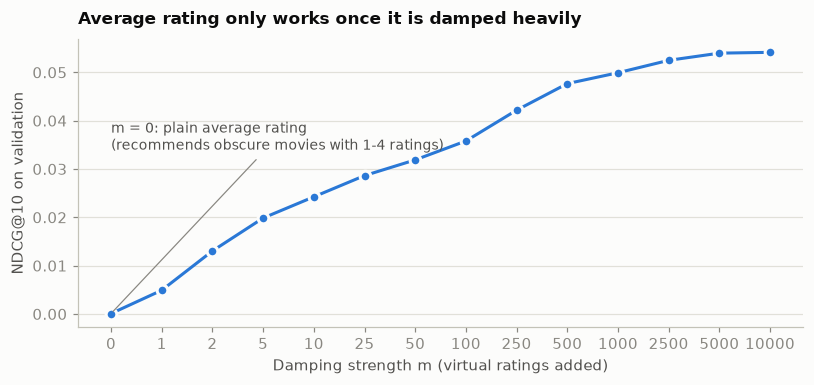

best m on validation = 10000 (NDCG@10 0.0541); plain average (m=0) = 0.0001
limit as m grows (rank by total rating above the average): NDCG@10 0.0549

Top 5 by PLAIN average rating:
                             title  train ratings
                   Lamerica (1994)              4
              Feast of July (1995)              1
       Hour of the Pig, The (1993)              1
Gate of Heavenly Peace, The (1995)              2
           Follow the Bitch (1998)              1

Top 5 by DAMPED average rating:
                                    title  train ratings
Star Wars: Episode IV - A New Hope (1977)           2537
                   American Beauty (1999)           3025
           Raiders of the Lost Ark (1981)           2132
         Shawshank Redemption, The (1994)           1814
                  Schindler's List (1993)           1944


array([[2651, 1108,  309, ..., 2374,   49, 1107],
       [ 253,  513,  802, ...,  287, 1485,  851],
       [ 309,  513,  802, ...,  593,  106,  287],
       ...,
       [ 253, 2651, 1108, ..., 1848,  579, 2374],
       [2651, 1108,  309, ...,  579, 2374, 2557],
       [2374, 1107,  106, ...,  346,  443, 1178]], shape=(5819, 10))

In [25]:
def damped_mean(m):
    """Weighted rating: pulls each movie's mean toward the global mean; m = how many 'virtual' ratings of global_mean to add."""
    v, total = rs["count"].to_numpy(), rs["sum"].to_numpy()
    return np.divide(total + m * global_mean, v + m, out=np.zeros(n_items), where=(v + m) > 0)

m_grid = [0, 1, 2, 5, 10, 25, 50, 100, 250, 500, 1000, 2500, 5000, 10000]
ndcg_by_m = pd.Series({m: val_ndcg(broadcast(damped_mean(m))) for m in m_grid})   # tuned on VALIDATION only
best_m = int(ndcg_by_m.idxmax())

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(m_grid))
ax.plot(x, ndcg_by_m.values, color=BLUE, lw=2, marker="o", ms=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xticks(x, [str(m) for m in m_grid])
ax.annotate("m = 0: plain average rating\n(recommends obscure movies with 1-4 ratings)", (0, ndcg_by_m.iloc[0]), xytext=(0, 0.034),
            color=INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set(title="Average rating only works once it is damped heavily", xlabel="Damping strength m (virtual ratings added)",
       ylabel="NDCG@10 on validation")
only_grid(ax, "y")
plt.tight_layout(); plt.show()

print(f"best m on validation = {best_m} (NDCG@10 {ndcg_by_m[best_m]:.4f}); plain average (m=0) = {ndcg_by_m[0]:.4f}")
# the best m sits at the edge of the grid, so check it is a plateau and not a missed optimum:
mass = rs["sum"].to_numpy() - rs["count"].to_numpy() * global_mean            # what the damped mean converges to as m grows
print(f"limit as m grows (rank by total rating above the average): NDCG@10 {val_ndcg(broadcast(mass)):.4f}")
print("\nTop 5 by PLAIN average rating:"); print(show_top(damped_mean(0), 5).to_string(index=False))
print("\nTop 5 by DAMPED average rating:"); print(show_top(damped_mean(best_m), 5).to_string(index=False))

evaluate_model("average rating (plain)", broadcast(damped_mean(0)), "val")
evaluate_model(f"average rating (damped, m={best_m})", broadcast(damped_mean(best_m)), "val")

In [26]:
u_info = users.set_index("user_id").loc[user_ids]
segment = (u_info.gender + "_" + u_info.age_code.astype(str)).to_numpy()      # e.g. "F_25": 2 genders x 7 age bands = 14 groups
global_share = liked_train.mean(axis=0)                                       # share of ALL users who liked each movie
seg_share = np.zeros((n_users, n_items), dtype=np.float32)
for s in np.unique(segment):
    idx = np.flatnonzero(segment == s)
    seg_share[idx] = liked_train[idx].mean(axis=0)                            # share of THIS group who liked each movie

alpha_grid = [0, 0.25, 0.5, 0.75, 1.0]                                        # 1 = ignore the group, 0 = group only
ndcg_by_alpha = pd.Series({a: val_ndcg(a * global_share + (1 - a) * seg_share) for a in alpha_grid})
best_alpha = float(ndcg_by_alpha.idxmax())
print(ndcg_by_alpha.round(4).to_string())
evaluate_model(f"popularity: by demographic group (alpha={best_alpha})",
               best_alpha * global_share + (1 - best_alpha) * seg_share, "val")

0.000   0.063
0.250   0.062
0.500   0.060
0.750   0.059
1.000   0.058


array([[   0, 2162,  574, ..., 1900, 2651,  581],
       [ 513,  802,  253, ..., 1485,  852, 1160],
       [2374, 1848,  575, ...,  287,  309,  513],
       ...,
       [2651,  513, 1104, ...,  802, 1563,  851],
       [ 513, 2651,  309, ..., 2557, 1106, 1108],
       [2374, 1107,  106, ...,  443,  466,    0]], shape=(5819, 10))

In [27]:
tbl = results_table("val").droplevel("split")
ceiling = tbl.loc["oracle (ceiling)"]
out = tbl[["precision@10", "recall@10", "hit_rate@10", "ndcg@10", "ndcg_ci95", "coverage", "diversity", "novelty"]].copy()
out["precision % of ceiling"] = tbl["precision@10"] / ceiling["precision@10"]

def paired_diff(a, b, split="val", metric="ndcg"):
    """Mean per-user difference a - b with a 95% margin of error. If |diff| > margin, the gap is not noise."""
    d = PER_USER[(a, split)][metric] - PER_USER[(b, split)][metric]
    return d.mean(), 1.96 * d.std(ddof=1) / np.sqrt(len(d))

demo = [n for n in tbl.index if n.startswith("popularity: by demographic")][0]
for a, b in [("popularity: most liked", "popularity: most rated"), (demo, "popularity: most rated")]:
    d, moe = paired_diff(a, b)
    print(f"NDCG@10 difference ({a}) - ({b}): {d:+.4f} +/- {moe:.4f}  -> {'real' if abs(d) > moe else 'within noise'}")

out.round(4)                                                                     # the table (last line, so the notebook shows it)

NDCG@10 difference (popularity: most liked) - (popularity: most rated): -0.0007 +/- 0.0012  -> within noise
NDCG@10 difference (popularity: by demographic group (alpha=0.0)) - (popularity: most rated): +0.0042 +/- 0.0019  -> real


,precision@10,recall@10,hit_rate@10,ndcg@10,ndcg_ci95,coverage,diversity,novelty,precision % of ceiling
model,,,,,,,,,
random (floor),0.003,0.003,0.027,0.003,0.001,1.000,0.828,6.794,0.004
oracle (ceiling),0.605,0.876,1.000,1.000,0.000,0.707,0.759,3.941,1.000
popularity: most rated,0.045,0.052,0.274,0.058,0.003,0.029,0.748,1.484,0.074
popularity: most liked,0.045,0.050,0.265,0.058,0.003,0.030,0.759,1.510,0.074
average rating (plain),0.000,0.000,0.001,0.000,0.000,0.003,0.756,12.160,0.000
"average rating (damped, m=10000)",0.042,0.048,0.247,0.054,0.003,0.030,0.781,1.627,0.069
popularity: by demographic group (alpha=0.0),0.048,0.055,0.286,0.063,0.003,0.052,0.768,1.630,0.080


In [28]:
best_name = tbl.drop(["random (floor)", "oracle (ceiling)"])["ndcg@10"].idxmax()     # strongest baseline so far
rows = EVAL_ROWS["val"]
hist = pd.qcut(seen_train.sum(axis=1)[rows], 4, labels=["lightest 25%", "25-50%", "50-75%", "heaviest 25%"])
by_hist = (pd.DataFrame({"ndcg": PER_USER[(best_name, "val")]["ndcg"], "recall": PER_USER[(best_name, "val")]["recall"],
                         "history": hist}).groupby("history", observed=True).mean())
print("best baseline:", best_name)
by_hist.round(4)

best baseline: popularity: by demographic group (alpha=0.0)


,ndcg,recall
history,,
lightest 25%,0.042,0.065
25-50%,0.047,0.055
50-75%,0.057,0.051
heaviest 25%,0.106,0.047


### What the baselines tell us
- **Popularity is a strong baseline.** Recommending the most-rated movies puts at least one liked movie in 27.4% of users' top-10 lists (NDCG@10 = 0.058, about 7% of the achievable Precision ceiling). Any learned model must clear this.
- **Plain average rating is useless as a ranker** (NDCG@10 = 0.0001): it surfaces movies with one to four ratings. Damping the average toward the global mean repairs it, but only once the damping is so strong that the list is again the most popular films. It plateaus near 0.055 and never beats popularity (0.058).
- **"Most liked" and "most rated" are equivalent** (difference -0.0007 ± 0.0012, within noise).
- **Demographics add a little.** Popularity within the user's gender and age group reaches NDCG@10 = 0.063, a small but real gain of +0.0042 ± 0.0019. This matches the EDA result that men's and women's genre mixes differ by at most 4.2 percentage points.
- **The cost of popularity is concentration.** All popularity models recommend only about 3% of the catalogue, and everyone sees nearly the same movies. Personalised models should increase coverage without losing accuracy.
- **Bar for later models:** NDCG@10 > 0.063 on validation, by more than the margin of error.

In [29]:
import io
import random
from pathlib import Path
import numpy as np
import pandas as pd

In [30]:
def read_dat(path: Path, names):
    """Read a '::'-separated file. Try UTF-8 first (valid for this copy), fall back to latin-1 (the official zip's encoding)."""
    raw = path.read_bytes()
    try:
        text = raw.decode("utf-8")
    except UnicodeDecodeError:
        text = raw.decode("latin-1")
    return pd.read_csv(io.StringIO(text), sep="::", engine="python", names=names)   # multi-char separator needs the python engine

def load_ml1m(data_dir: Path):
    """Read the three MovieLens-1M files into tidy DataFrames."""
    ratings = read_dat(data_dir / "ratings.dat", ["user_id", "movie_id", "rating", "timestamp"])
    movies = read_dat(data_dir / "movies.dat", ["movie_id", "title", "genres"])
    users = read_dat(data_dir / "users.dat", ["user_id", "gender", "age_code", "occupation_code", "zip"])
    movies["title"] = movies["title"].str.replace("\ufffd", "?", regex=False)      # accents already destroyed in this copy (62 characters)

    ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
    movies["year"] = movies["title"].str.extract(r"\((\d{4})\)\s*$")[0].astype("Int64")
    movies["genre_list"] = movies["genres"].str.split("|")
    users["age"] = users["age_code"].map(AGE_LABELS)
    users["occupation"] = users["occupation_code"].map(OCC_LABELS)
    return ratings, movies, users

## 5. Content-based model

A content-based recommender describes each movie by its attributes (genres, release decade), builds each user's taste profile by averaging the movies they liked, and recommends the movies most similar to that profile (cosine similarity). It works for any movie with attributes, even one nobody has rated yet, which makes it important for cold start.
Movie attributes use no ratings, so describing all movies (including ones that only appear later) leaks nothing.

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

genre_names = sorted(gx.genre_list.unique())                            # same order as the columns of genre_mat (Step 3)
assert genre_mat.shape[1] == len(genre_names)
mv = movies.set_index("movie_id").loc[item_ids]

G = genre_mat                                                           # items x 18: 1 if the movie has that genre
idf = np.log(n_items / (1 + G.sum(axis=0)))                             # rare genres (Film-Noir) say more about taste than Drama
decade = ((mv.year.astype(int) // 10) * 10).clip(lower=1910)
decade_names = [f"{d}s" for d in sorted(decade.unique())]
D = pd.get_dummies(decade).to_numpy(dtype=np.float32)                   # items x decades
clean_title = mv.title.str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)  # drop the "(1995)" part
T = TfidfVectorizer(stop_words="english", min_df=2).fit_transform(clean_title).toarray().astype(np.float32)   # title words

n_distinct = len({tuple(row) for row in G.astype(int)})
print(f"{G.shape[1]} genres, {D.shape[1]} decades, {T.shape[1]} title words")
print(f"only {n_distinct} distinct genre combinations among {n_items:,} movies -> many movies look identical to a genre-only model")
print(f"movies with no usable title word: {(T.sum(axis=1) == 0).sum():,}")

18 genres, 10 decades, 1151 title words
only 301 distinct genre combinations among 3,706 movies -> many movies look identical to a genre-only model
movies with no usable title word: 965


In [32]:
def item_matrix(w_genre=1.0, w_decade=0.0, w_title=0.0, use_idf=False):
    """Stack the feature blocks (each scaled to unit length, then weighted) into one unit-length vector per movie."""
    g = normalize(G * idf) if use_idf else normalize(G)
    blocks = [w_genre * g]
    if w_decade: blocks.append(w_decade * normalize(D))
    if w_title: blocks.append(w_title * normalize(T))
    return normalize(np.hstack(blocks)).astype(np.float32)              # unit length -> dot product = cosine similarity

# how much each user liked each training movie
W_liked = liked_train.astype(np.float32)                                # 1 if the user rated it 4-5 stars
ur = u_pos.loc[train.user_id.to_numpy()].to_numpy(); ic = i_pos.loc[train.movie_id.to_numpy()].to_numpy()
user_mean = train.groupby("user_id").rating.mean().reindex(user_ids).to_numpy()
W_cent = np.zeros((n_users, n_items), dtype=np.float32)
W_cent[ur, ic] = train.rating.to_numpy() - user_mean[ur]                # rating minus the user's own average (dislikes go negative)

pop_norm = (train_n / train_n.max()).astype(np.float32)                 # popularity scaled to 0-1

def cosine_scores(X, W=W_liked):
    """Profile = the user's liked movies averaged in feature space; score = cosine(profile, movie)."""
    P = normalize(W @ X)
    return P @ X.T, P

def with_tie_break(C):
    """Many movies share identical features; break those exact ties by popularity (a tiny nudge, not a real blend)."""
    return C + 1e-4 * pop_norm

1. genres, ties broken by movie id    0.0112
2. + ties broken by popularity        0.0270
3. + rare genres weighted up (idf)    0.0285
4. + decade of release                0.0294
5. + title words                      0.0195
6. (4) with rating-centred profile    0.0223


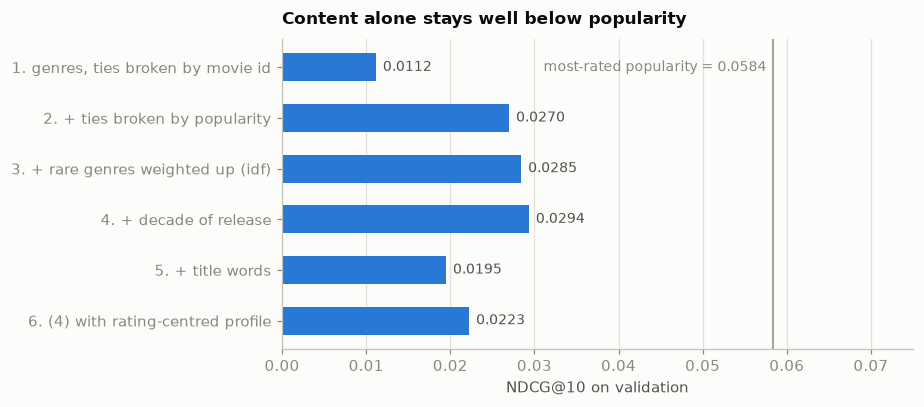

In [33]:
X_genre, X_idf = item_matrix(), item_matrix(use_idf=True)
X_idf_dec = item_matrix(w_decade=0.5, use_idf=True)
X_idf_dec_title = item_matrix(w_decade=0.5, w_title=0.5, use_idf=True)

ablation = pd.Series({
    "1. genres, ties broken by movie id":            val_ndcg(cosine_scores(X_genre)[0]),
    "2. + ties broken by popularity":                val_ndcg(with_tie_break(cosine_scores(X_genre)[0])),
    "3. + rare genres weighted up (idf)":            val_ndcg(with_tie_break(cosine_scores(X_idf)[0])),
    "4. + decade of release":                        val_ndcg(with_tie_break(cosine_scores(X_idf_dec)[0])),
    "5. + title words":                              val_ndcg(with_tie_break(cosine_scores(X_idf_dec_title)[0])),
    "6. (4) with rating-centred profile":            val_ndcg(with_tie_break(cosine_scores(X_idf_dec, W_cent)[0])),
})
pop_ndcg = results_table("val").loc[("popularity: most rated", "val"), "ndcg@10"]

fig, ax = plt.subplots(figsize=(8.5, 3.8))
yy = np.arange(len(ablation))[::-1]
ax.barh(yy, ablation.values, height=0.55, color=BLUE)
for y_, v in zip(yy, ablation.values):
    ax.text(v + 0.0008, y_, f"{v:.4f}", va="center", color=INK2, fontsize=9)
ax.axvline(pop_ndcg, color=MUTED, lw=1)
ax.text(pop_ndcg - 0.0008, yy[0], f"most-rated popularity = {pop_ndcg:.4f}", color=MUTED, fontsize=9, ha="right", va="center")
print(ablation.map("{:.4f}".format).to_string())
ax.set_yticks(yy, ablation.index)
ax.set(title="Content alone stays well below popularity", xlabel="NDCG@10 on validation", xlim=(0, 0.075))
only_grid(ax, "x")
plt.tight_layout(); plt.show()

In [34]:
C_content, P_content = cosine_scores(X_idf_dec)                         # pure similarity (no tie-break)
evaluate_model("content-based (genres + decade)", with_tie_break(C_content), "val")

lam_grid = [0.03, 0.1, 0.3, 1, 3, 10]                                   # weight on raw popularity added to the similarity
ndcg_by_lam = pd.Series({lam: val_ndcg(C_content + lam * pop_norm) for lam in lam_grid})   # tuned on VALIDATION only
best_lam = float(ndcg_by_lam.idxmax())
print(ndcg_by_lam.round(4).to_string())
_ = evaluate_model(f"content + popularity prior (lambda={best_lam:g})", C_content + best_lam * pop_norm, "val")   # "_ =" stops the notebook printing the array

0.030    0.031
0.100    0.036
0.300    0.049
1.000    0.068
3.000    0.063
10.000   0.059


In [35]:
tbl = results_table("val").droplevel("split")
cols = ["precision@10", "recall@10", "hit_rate@10", "ndcg@10", "ndcg_ci95", "coverage", "diversity", "novelty"]
out = tbl[cols].copy()

content_only = "content-based (genres + decade)"
blend = f"content + popularity prior (lambda={best_lam:g})"
demo = [n for n in tbl.index if n.startswith("popularity: by demographic")][0]
for a, b in [(content_only, "popularity: most rated"), (blend, "popularity: most rated"), (blend, demo)]:
    d, moe = paired_diff(a, b)
    print(f"NDCG@10  {a}  minus  {b}: {d:+.4f} +/- {moe:.4f}  -> {'real' if abs(d) > moe else 'within noise'}")

out.round(4)

NDCG@10  content-based (genres + decade)  minus  popularity: most rated: -0.0290 +/- 0.0039  -> real
NDCG@10  content + popularity prior (lambda=1)  minus  popularity: most rated: +0.0096 +/- 0.0028  -> real
NDCG@10  content + popularity prior (lambda=1)  minus  popularity: by demographic group (alpha=0.0): +0.0054 +/- 0.0032  -> real


,precision@10,recall@10,hit_rate@10,ndcg@10,ndcg_ci95,coverage,diversity,novelty
model,,,,,,,,
random (floor),0.003,0.003,0.027,0.003,0.001,1.000,0.828,6.794
oracle (ceiling),0.605,0.876,1.000,1.000,0.000,0.707,0.759,3.941
popularity: most rated,0.045,0.052,0.274,0.058,0.003,0.029,0.748,1.484
popularity: most liked,0.045,0.050,0.265,0.058,0.003,0.030,0.759,1.510
average rating (plain),0.000,0.000,0.001,0.000,0.000,0.003,0.756,12.160
"average rating (damped, m=10000)",0.042,0.048,0.247,0.054,0.003,0.030,0.781,1.627
popularity: by demographic group (alpha=0.0),0.048,0.055,0.286,0.063,0.003,0.052,0.768,1.630
content-based (genres + decade),0.018,0.032,0.142,0.029,0.002,0.526,0.128,4.283
content + popularity prior (lambda=1),0.047,0.071,0.322,0.068,0.003,0.140,0.646,1.902


In [36]:
feature_names = genre_names + decade_names
assert X_idf_dec.shape[1] == len(feature_names)

def explain(user_row, item_col, top=2):
    """The features that contribute most to the match between this user's taste profile and this movie."""
    contrib = P_content[user_row] * X_idf_dec[item_col]
    best = np.argsort(-contrib)[:top]
    return " + ".join(feature_names[b] for b in best if contrib[b] > 0)

rows = EVAL_ROWS["val"]
hist_n = seen_train.sum(axis=1)
pick = rows[np.argmin(np.abs(hist_n[rows] - np.median(hist_n[rows])))]           # a typical user: median amount of history
uid = user_ids[pick]
favourites = train[(train.user_id == uid) & (train.rating == 5)].movie_id.map(titles).head(6).tolist()
print(f"User {uid} ({hist_n[pick]} training ratings). Some 5-star movies: {favourites}\n")

recs_all = get_recs(with_tie_break(C_content))
my_recs = recs_all[np.flatnonzero(rows == pick)[0]][:5]
pd.DataFrame({
    "recommended": [titles[item_ids[j]] for j in my_recs],
    "because (matching features)": [explain(pick, j) for j in my_recs],
    "liked later?": ["yes" if rel_val[pick, j] else "no" for j in my_recs],
})

User 38 (70 training ratings). Some 5-star movies: ['Jerry Maguire (1996)', 'Shakespeare in Love (1998)', 'Immortal Beloved (1994)', 'Four Weddings and a Funeral (1994)', 'English Patient, The (1996)', 'Life Is Beautiful (La Vita è bella) (1997)']



,recommended,because (matching features),liked later?
0,"American President, The (1995)",Romance + 1990s,no
1,"Fisher King, The (1991)",Romance + 1990s,no
2,Singles (1992),Romance + 1990s,no
3,"Corrina, Corrina (1994)",Romance + 1990s,no
4,Brassed Off (1996),Romance + 1990s,no


### What the content-based model tells us
- **Genres alone cannot tell movies apart.** Only 301 distinct genre combinations exist among 3,706 movies, so many movies get identical scores. Breaking ties by popularity instead of movie id more than doubles NDCG@10 (0.011 to 0.027), which shows how coarse the features are.
- **Rare genres and release decade help slightly** (0.0270 to 0.0294). Title words and a rating-centred profile hurt (0.0195 and 0.0223), so we leave them out.
- **Content alone is clearly worse than popularity** (NDCG@10 0.029 vs 0.058, difference -0.0290 ± 0.0039). Its lists are also almost uniform in genre (diversity 0.128 vs 0.748).
- **Content adds value on top of popularity.** Adding a popularity prior (λ = 1) gives NDCG@10 = 0.068, +0.0096 ± 0.0028 over most-rated and +0.0054 ± 0.0032 over demographic popularity, and raises catalogue coverage from 3% to 14%. Content and popularity carry different signals, which motivates the hybrid model in Step 7.
- **The model is explainable by construction:** each recommendation can be traced to the genres and decade that matched the user's taste profile. We will build on this in the explanation step.
- **Limitation:** the "popularity prior" weight was tuned on validation, so the 0.068 is slightly optimistic until confirmed on the test set at the end.

## 6. Collaborative filtering: learning from other users' ratings

Content-based models only know what a movie *is*. Collaborative filtering knows who watched it and liked it, so it can say "people who liked what you liked also liked this", without knowing anything about genres.

I try three classic approaches, all fitted on the **training split only**:
1. **Item-based nearest neighbours**: two movies are similar if many of the same users rated both.
2. **PureSVD**: compress the user x movie matrix into a few "taste axes" and score movies along them.
3. **Implicit ALS**: learn a hidden taste vector per user and per movie, so that liked movies get a high dot product. Written from scratch.

Hyperparameters are tuned on validation only. The test split stays untouched.

In [37]:
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

R_all = seen_train.astype(np.float32)        # users x movies: 1 if the user rated the movie (any rating)
R_lik = liked_train.astype(np.float32)       # users x movies: 1 if the user rated it 4-5 stars
print(f"{int(R_all.sum()):,} rated pairs, {int(R_lik.sum()):,} liked pairs, density {R_all.mean():.2%}")

699,920 rated pairs, 416,202 liked pairs, density 3.13%


In [38]:
def item_similarity(R, alpha=0.5):
    """Cosine-style similarity between movies: how often the same users rate both, relative to how often each is rated."""
    co = R.T @ R                                     # co[i, j] = number of users who rated both movie i and movie j
    n = np.diag(co) + 1e-9                           # n[i]    = number of users who rated movie i
    sim = co / (np.power(n, alpha)[:, None] * np.power(n, 1 - alpha)[None, :])   # alpha = 0.5 is plain cosine
    np.fill_diagonal(sim, 0)                         # a movie is not its own neighbour
    return sim.astype(np.float32)

knn_variants = {                                     # (matrix used for similarity, matrix used as user profile, alpha)
    "A. similarity from all ratings, profile = liked movies":  (R_all, R_lik, 0.5),
    "B. similarity from liked only, profile = liked movies":   (R_lik, R_lik, 0.5),
    "C. similarity from all ratings, profile = all rated":     (R_all, R_all, 0.5),
    "D. as A, alpha = 0.3":                                    (R_all, R_lik, 0.3),
    "E. as A, alpha = 0.7":                                    (R_all, R_lik, 0.7),
}
knn_ndcg = pd.Series({name: val_ndcg(Rp @ item_similarity(Rs, a)) for name, (Rs, Rp, a) in knn_variants.items()})
print(knn_ndcg.map("{:.4f}".format).to_string())

sim_knn = item_similarity(R_all)                     # final choice: variant A
S_knn = R_lik @ sim_knn                              # score of movie j for user u = sum of similarity(j, each movie u liked)
_ = evaluate_model("item-kNN (cosine)", S_knn, "val")

# sanity check: are the neighbours sensible?
title_to_col = {titles[m]: c for c, m in enumerate(item_ids)}
def similar_to(title, n=5):
    return [titles[item_ids[c]] for c in np.argsort(-sim_knn[title_to_col[title]])[:n]]
for t in ["Toy Story (1995)", "Godfather, The (1972)", "Alien (1979)"]:
    print(f"\nMost similar to {t}:\n  " + "\n  ".join(similar_to(t)))

A. similarity from all ratings, profile = liked movies    0.0935
B. similarity from liked only, profile = liked movies     0.0862
C. similarity from all ratings, profile = all rated       0.0886
D. as A, alpha = 0.3                                      0.0881
E. as A, alpha = 0.7                                      0.0818

Most similar to Toy Story (1995):
  Groundhog Day (1993)
  Toy Story 2 (1999)
  Aladdin (1992)
  Babe (1995)
  Bug's Life, A (1998)

Most similar to Godfather, The (1972):
  Godfather: Part II, The (1974)
  Star Wars: Episode IV - A New Hope (1977)
  Star Wars: Episode V - The Empire Strikes Back (1980)
  Raiders of the Lost Ark (1981)
  Jaws (1975)

Most similar to Alien (1979):
  Aliens (1986)
  Terminator, The (1984)
  Star Wars: Episode IV - A New Hope (1977)
  Star Wars: Episode V - The Empire Strikes Back (1980)
  Jaws (1975)


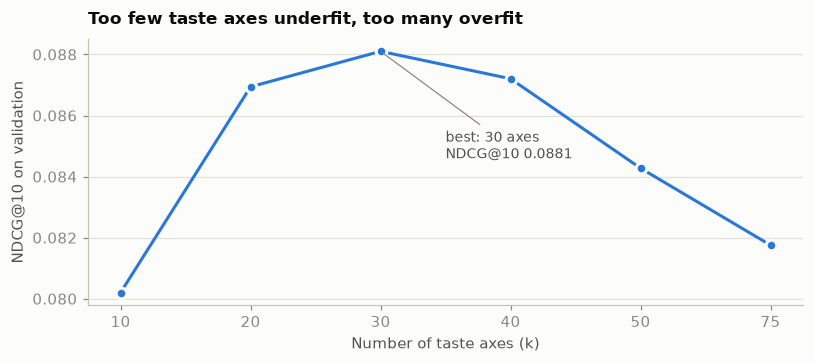

In [39]:
k_grid = [10, 20, 30, 40, 50, 75]
svd_ndcg, svd_vt = {}, {}
for k in k_grid:
    _, _, Vt = svds(csr_matrix(R_lik), k=k, random_state=SEED)     # Vt: k taste axes, each a weight per movie
    svd_vt[k] = Vt
    svd_ndcg[k] = val_ndcg((R_lik @ Vt.T) @ Vt)                      # project the user's likes onto the axes and map back
svd_ndcg = pd.Series(svd_ndcg)
best_k = int(svd_ndcg.idxmax())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(range(len(k_grid)), svd_ndcg.values, color=BLUE, lw=2, marker="o", ms=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xticks(range(len(k_grid)), [str(k) for k in k_grid])
ax.annotate(f"best: {best_k} axes\nNDCG@10 {svd_ndcg[best_k]:.4f}", (k_grid.index(best_k), svd_ndcg[best_k]),
            xytext=(k_grid.index(best_k) + 0.5, svd_ndcg[best_k] - 0.0035), color=INK2, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set(title="Too few taste axes underfit, too many overfit", xlabel="Number of taste axes (k)", ylabel="NDCG@10 on validation")
only_grid(ax, "y")
plt.tight_layout(); plt.show()

S_svd = (R_lik @ svd_vt[best_k].T) @ svd_vt[best_k]
_ = evaluate_model(f"PureSVD (k={best_k})", S_svd, "val")

ALS reg=50                   NDCG@10 after iterations 3: 0.0833, 6: 0.0840, 9: 0.0851, 12: 0.0860, 15: 0.0862
ALS reg=100                  NDCG@10 after iterations 3: 0.0865, 6: 0.0870, 9: 0.0877, 12: 0.0888, 15: 0.0890
ALS reg=200                  NDCG@10 after iterations 3: 0.0818, 6: 0.0858, 9: 0.0869, 12: 0.0873, 15: 0.0876
ALS reg=100, no negatives    NDCG@10 after iterations 3: 0.0857, 6: 0.0860, 9: 0.0870, 12: 0.0868, 15: 0.0871

best ALS configuration: reg=100


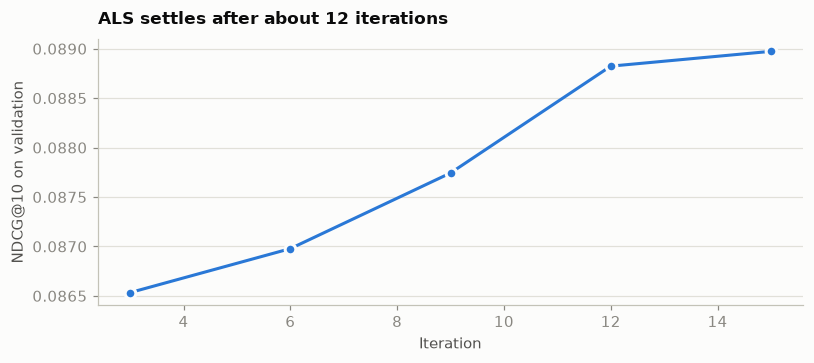

In [40]:
rt = train.rating.to_numpy()
def als_inputs(alpha=15.0, alpha_neg=5.0):
    """Liked movies: preference 1, confidence 1+alpha. Disliked (1-2 stars): preference 0 with confidence 1+alpha_neg
    (a confident 'no'). 3-star ratings are ignored (we do not know whether they are a yes or a no)."""
    w = np.where(rt >= 4, alpha, np.where(rt <= 2, alpha_neg, 0.0))           # confidence minus 1
    keep = w > 0
    conf_minus_1 = csr_matrix((w[keep], (ur[keep], ic[keep])), shape=(n_users, n_items))
    pos = rt >= 4
    target = csr_matrix(((1 + alpha) * np.ones(pos.sum()), (ur[pos], ic[pos])), shape=(n_users, n_items))   # confidence * preference
    return conf_minus_1, target

def als_implicit(conf_minus_1, target, factors=64, reg=100.0, iters=15, seed=SEED, eval_every=3):
    """Alternating least squares for implicit feedback (Hu, Koren & Volinsky 2008).
    Each step fixes one side (users or movies) and solves a small least-squares problem exactly for every row of the other side."""
    rng = np.random.default_rng(seed)
    X = rng.normal(0, 0.01, (n_users, factors)); Y = rng.normal(0, 0.01, (n_items, factors))
    by_user = (conf_minus_1.tocsr(), target.tocsr()); by_item = (conf_minus_1.T.tocsr(), target.T.tocsr())
    ridge = reg * np.eye(factors)

    def solve(Cm, Tg, F):                              # F = the side that is held fixed
        FtF = F.T @ F + ridge                          # contribution of ALL movies with confidence 1
        rhs = Tg @ F
        out = np.empty((Cm.shape[0], factors))
        for r in range(Cm.shape[0]):
            s, e = Cm.indptr[r], Cm.indptr[r + 1]      # the movies this user rated 4-5 or 1-2
            Fr = F[Cm.indices[s:e]]
            out[r] = np.linalg.solve(FtF + (Fr.T * Cm.data[s:e]) @ Fr, rhs[r])   # add the extra confidence of the rated ones
        return out

    curve = []
    for it in range(1, iters + 1):
        X = solve(*by_user, Y)
        Y = solve(*by_item, X)
        if it % eval_every == 0:
            curve.append((it, val_ndcg(X @ Y.T)))
    return X, Y, curve

als_runs = {}
for label, reg, alpha_neg in [("reg=50", 50, 5), ("reg=100", 100, 5), ("reg=200", 200, 5), ("reg=100, no negatives", 100, 0)]:
    X_, Y_, curve = als_implicit(*als_inputs(15.0, alpha_neg), reg=reg)
    als_runs[label] = (X_, Y_, curve)
    print(f"ALS {label:24s} NDCG@10 after iterations " + ", ".join(f"{i}: {v:.4f}" for i, v in curve))

best_als = max(als_runs, key=lambda k: als_runs[k][2][-1][1])
X_als, Y_als, curve = als_runs[best_als]
print("\nbest ALS configuration:", best_als)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot([i for i, _ in curve], [v for _, v in curve], color=BLUE, lw=2, marker="o", ms=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set(title="ALS settles after about 12 iterations", xlabel="Iteration", ylabel="NDCG@10 on validation")
only_grid(ax, "y")
plt.tight_layout(); plt.show()

S_als = X_als @ Y_als.T
_ = evaluate_model(f"ALS implicit (64 factors, {best_als})", S_als, "val")

NDCG@10  item-kNN (cosine)  minus  popularity: by demographic group (alpha=0.0): +0.0308 +/- 0.0040  -> real
NDCG@10  item-kNN (cosine)  minus  ALS implicit (64 factors, reg=100): +0.0045 +/- 0.0036  -> real
NDCG@10  item-kNN (cosine)  minus  PureSVD (k=30): +0.0054 +/- 0.0035  -> real
NDCG@10  ALS implicit (64 factors, reg=100)  minus  PureSVD (k=30): +0.0009 +/- 0.0028  -> within noise


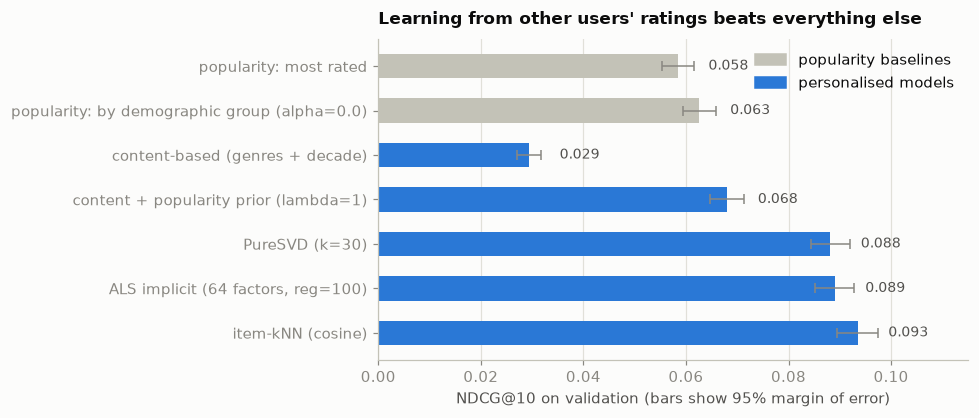

,precision@10,recall@10,hit_rate@10,ndcg@10,ndcg_ci95,coverage,diversity,novelty
model,,,,,,,,
random (floor),0.003,0.003,0.027,0.003,0.001,1.000,0.828,6.794
oracle (ceiling),0.605,0.876,1.000,1.000,0.000,0.707,0.759,3.941
popularity: most rated,0.045,0.052,0.274,0.058,0.003,0.029,0.748,1.484
popularity: most liked,0.045,0.050,0.265,0.058,0.003,0.030,0.759,1.510
average rating (plain),0.000,0.000,0.001,0.000,0.000,0.003,0.756,12.160
"average rating (damped, m=10000)",0.042,0.048,0.247,0.054,0.003,0.030,0.781,1.627
popularity: by demographic group (alpha=0.0),0.048,0.055,0.286,0.063,0.003,0.052,0.768,1.630
content-based (genres + decade),0.018,0.032,0.142,0.029,0.002,0.526,0.128,4.283
content + popularity prior (lambda=1),0.047,0.071,0.322,0.068,0.003,0.140,0.646,1.902


In [41]:
tbl = results_table("val").droplevel("split")
names = {m: n for m, n in zip(["most", "demo", "content", "blend", "knn", "svd", "als"],
         ["popularity: most rated", [n for n in tbl.index if n.startswith("popularity: by demographic")][0],
          "content-based (genres + decade)", [n for n in tbl.index if n.startswith("content + popularity")][0],
          "item-kNN (cosine)", f"PureSVD (k={best_k})", [n for n in tbl.index if n.startswith("ALS implicit")][0]])}

for a, b in [("knn", "demo"), ("knn", "als"), ("knn", "svd"), ("als", "svd")]:
    d, moe = paired_diff(names[a], names[b])
    print(f"NDCG@10  {names[a]}  minus  {names[b]}: {d:+.4f} +/- {moe:.4f}  -> {'real' if abs(d) > moe else 'within noise'}")

board = tbl.loc[[names[k] for k in ["most", "demo", "content", "blend", "svd", "als", "knn"]]]
fig, ax = plt.subplots(figsize=(9, 3.9))
yy = np.arange(len(board))[::-1]
is_baseline = board.index.str.startswith("popularity")
ax.barh(yy, board["ndcg@10"], xerr=board["ndcg_ci95"], height=0.55,
        color=[GRAY if b else BLUE for b in is_baseline], error_kw=dict(ecolor=MUTED, lw=1, capsize=3))
for y_, v in zip(yy, board["ndcg@10"]):
    ax.text(v + 0.006, y_, f"{v:.3f}", va="center", color=INK2, fontsize=9)
ax.set_yticks(yy, board.index)
ax.legend(handles=[Patch(color=GRAY, label="popularity baselines"), Patch(color=BLUE, label="personalised models")], loc="upper right")
ax.set(title="Learning from other users' ratings beats everything else", xlabel="NDCG@10 on validation (bars show 95% margin of error)", xlim=(0, 0.115))
only_grid(ax, "x")
plt.tight_layout(); plt.show()

cols = ["precision@10", "recall@10", "hit_rate@10", "ndcg@10", "ndcg_ci95", "coverage", "diversity", "novelty"]
tbl[cols].round(4)

In [42]:
pos = np.flatnonzero(rows == pick)[0]                                 # `rows`, `pick`, `uid` come from Step 5, cell 6
for name, S in [("most-rated popularity", broadcast(train_n)), ("content-based", with_tie_break(C_content)),
                ("item-kNN", S_knn), ("PureSVD", S_svd), ("ALS", S_als)]:
    hits = int(rel_val[pick, get_recs(S)[pos]].sum())
    print(f"{name:24s} hits in the top 10 for user {uid}: {hits}")

def because_you_liked(user_row, item_col):
    """The movie this user liked that is most similar to the recommended movie."""
    contrib = R_lik[user_row] * sim_knn[:, item_col]
    return titles[item_ids[int(np.argmax(contrib))]]

knn_recs = get_recs(S_knn)[pos][:5]
pd.DataFrame({
    "recommended": [titles[item_ids[j]] for j in knn_recs],
    "because you liked": [because_you_liked(pick, j) for j in knn_recs],
    "liked later?": ["yes" if rel_val[pick, j] else "no" for j in knn_recs],
})

most-rated popularity    hits in the top 10 for user 38: 0
content-based            hits in the top 10 for user 38: 0
item-kNN                 hits in the top 10 for user 38: 0
PureSVD                  hits in the top 10 for user 38: 0
ALS                      hits in the top 10 for user 38: 0


,recommended,because you liked,liked later?
0,Groundhog Day (1993),Shakespeare in Love (1998),no
1,Pretty Woman (1990),Sleepless in Seattle (1993),no
2,"American President, The (1995)",Sleepless in Seattle (1993),no
3,You've Got Mail (1998),Sleepless in Seattle (1993),no
4,As Good As It Gets (1997),Forrest Gump (1994),no


## 7. Hybrid: combining the collaborative models

Item-kNN and ALS make different mistakes: kNN trusts movies that are directly co-rated with the user's likes, while ALS learns hidden taste dimensions. Averaging them should cancel some errors.

Raw scores from different models are on different scales, so for each user I convert every model's scores to z-scores over the movies they have not seen, then take a weighted sum. The weight is tuned on **validation only**. I also check that:
- the chosen weight is the same on two random halves of the validation users,
- adding content, popularity or demographic scores on top gives any further gain.

In [43]:
def zscore_unseen(S, seen):
    """Per user: subtract the mean and divide by the std of the scores over the movies the user has NOT seen.
    Raw scores of different models live on different scales (similarity sums, dot products, shares), so they cannot be added directly."""
    S = np.asarray(S, dtype=np.float32); m = ~seen.astype(bool); cnt = m.sum(axis=1, keepdims=True)
    mu = (S * m).sum(axis=1, keepdims=True) / cnt
    sd = np.sqrt((((S - mu) * m) ** 2).sum(axis=1, keepdims=True) / cnt) + 1e-9
    return (S - mu) / sd

Z = {"knn": zscore_unseen(S_knn, seen_train), "als": zscore_unseen(S_als, seen_train), "svd": zscore_unseen(S_svd, seen_train),
     "content": zscore_unseen(C_content, seen_train), "popularity": zscore_unseen(broadcast(train_n), seen_train),
     "demographic": zscore_unseen(seg_share, seen_train)}
print("NDCG@10 of each component after rescaling (rescaling must not change a single model's ranking):")
print(pd.Series({k: val_ndcg(v) for k, v in Z.items()}).map("{:.4f}".format).to_string())

NDCG@10 of each component after rescaling (rescaling must not change a single model's ranking):
knn            0.0935
als            0.0890
svd            0.0881
content        0.0129
popularity     0.0584
demographic    0.0626


0.000    0.0935
0.100    0.0989
0.200    0.0998
0.300    0.1003
0.500    0.0989
0.750    0.0977
1.000    0.0962
1.500    0.0947


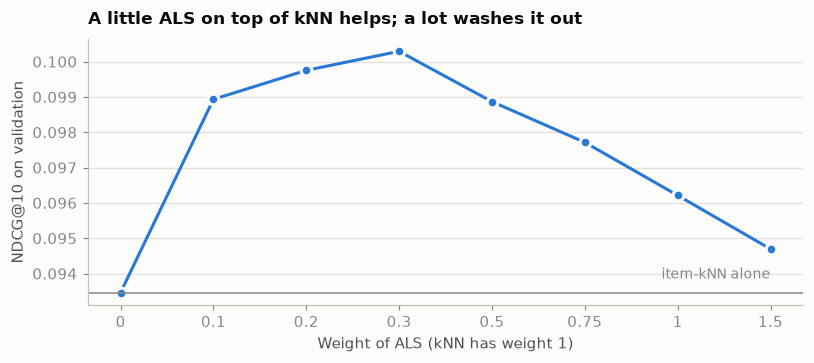

In [44]:
w_grid = [0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5]
by_w = pd.Series({w: val_ndcg(Z["knn"] + w * Z["als"]) for w in w_grid})
best_w = float(by_w.idxmax())
print(by_w.map("{:.4f}".format).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(range(len(w_grid)), by_w.values, color=BLUE, lw=2, marker="o", ms=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_xticks(range(len(w_grid)), [f"{w:g}" for w in w_grid])
ax.axhline(by_w[0], color=MUTED, lw=1)
ax.text(len(w_grid) - 1, by_w[0] + 0.0004, "item-kNN alone", color=MUTED, fontsize=9, ha="right")
ax.set(title="A little ALS on top of kNN helps; a lot washes it out", xlabel="Weight of ALS (kNN has weight 1)", ylabel="NDCG@10 on validation")
only_grid(ax, "y")
plt.tight_layout(); plt.show()

In [45]:
base = Z["knn"] + best_w * Z["als"]
extra_grid = [0.1, 0.25, 0.5, 1.0]
extra = pd.DataFrame({k: {w: val_ndcg(base + w * Z[k]) for w in extra_grid} for k in ["svd", "content", "popularity", "demographic"]})
extra.index.name = "weight"
print(f"reference (kNN + {best_w:g} ALS): {by_w[best_w]:.4f}")
extra.round(4)

reference (kNN + 0.3 ALS): 0.1003


,svd,content,popularity,demographic
weight,,,,
0.100,0.099,0.099,0.098,0.098
0.250,0.096,0.098,0.090,0.090
0.500,0.094,0.095,0.081,0.081
1.000,0.091,0.088,0.072,0.072


In [46]:
rows = EVAL_ROWS["val"]
perm = np.random.default_rng(SEED).permutation(len(rows)); half_a, half_b = perm[: len(rows) // 2], perm[len(rows) // 2:]
def per_user_ndcg(S):
    return ranking_metrics(get_recs(S), rel_val[rows], K)["ndcg"]
curves = {w: per_user_ndcg(Z["knn"] + w * Z["als"]) for w in w_grid}
for name, idx in [("half A", half_a), ("half B", half_b)]:
    s = pd.Series({w: c[idx].mean() for w, c in curves.items()})
    print(f"{name}: best weight = {s.idxmax():g}  (NDCG@10 {s.max():.4f}; kNN alone {s[0]:.4f})")

half A: best weight = 0.3  (NDCG@10 0.1007; kNN alone 0.0939)
half B: best weight = 0.3  (NDCG@10 0.0999; kNN alone 0.0930)


NDCG@10  hybrid: item-kNN + 0.3 x ALS  minus  item-kNN (cosine): +0.0068 +/- 0.0024  -> real
NDCG@10  hybrid: item-kNN + 0.3 x ALS  minus  ALS implicit (64 factors, reg=100): +0.0113 +/- 0.0024  -> real
NDCG@10  hybrid: item-kNN + 0.3 x ALS  minus  popularity: by demographic group (alpha=0.0): +0.0377 +/- 0.0042  -> real


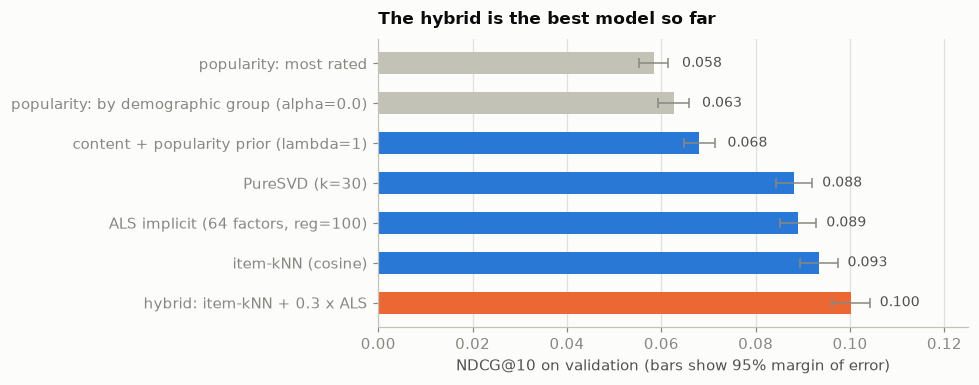

,precision@10,recall@10,hit_rate@10,ndcg@10,ndcg_ci95,coverage,diversity,novelty
model,,,,,,,,
popularity: by demographic group (alpha=0.0),0.048,0.055,0.286,0.063,0.003,0.052,0.768,1.630
item-kNN (cosine),0.065,0.096,0.397,0.093,0.004,0.151,0.726,1.990
PureSVD (k=30),0.060,0.097,0.394,0.088,0.004,0.173,0.744,2.410
"ALS implicit (64 factors, reg=100)",0.060,0.102,0.403,0.089,0.004,0.278,0.726,2.556
hybrid: item-kNN + 0.3 x ALS,0.070,0.109,0.429,0.100,0.004,0.193,0.729,2.157


In [47]:
HYBRID = f"hybrid: item-kNN + {best_w:g} x ALS"
S_hybrid = Z["knn"] + best_w * Z["als"]
_ = evaluate_model(HYBRID, S_hybrid, "val")

tbl = results_table("val").droplevel("split")
for a, b in [(HYBRID, "item-kNN (cosine)"), (HYBRID, names["als"]), (HYBRID, names["demo"])]:
    d, moe = paired_diff(a, b)
    print(f"NDCG@10  {a}  minus  {b}: {d:+.4f} +/- {moe:.4f}  -> {'real' if abs(d) > moe else 'within noise'}")

order = ["most", "demo", "blend", "svd", "als", "knn"]
board = pd.concat([tbl.loc[[names[k] for k in order]], tbl.loc[[HYBRID]]])
fig, ax = plt.subplots(figsize=(9, 3.6))
yy = np.arange(len(board))[::-1]
colors = [GRAY if n.startswith("popularity") else (ORANGE if n == HYBRID else BLUE) for n in board.index]
ax.barh(yy, board["ndcg@10"], xerr=board["ndcg_ci95"], height=0.55, color=colors, error_kw=dict(ecolor=MUTED, lw=1, capsize=3))
for y_, v in zip(yy, board["ndcg@10"]):
    ax.text(v + 0.006, y_, f"{v:.3f}", va="center", color=INK2, fontsize=9)
ax.set_yticks(yy, board.index)
ax.set(title="The hybrid is the best model so far", xlabel="NDCG@10 on validation (bars show 95% margin of error)", xlim=(0, 0.125))
only_grid(ax, "x")
plt.tight_layout(); plt.show()

cols = ["precision@10", "recall@10", "hit_rate@10", "ndcg@10", "ndcg_ci95", "coverage", "diversity", "novelty"]
tbl.loc[[names["demo"], names["knn"], names["svd"], names["als"], HYBRID], cols].round(4)

In [48]:
history = seen_train.sum(axis=1)[rows]
bucket = pd.qcut(history, 4, labels=["lightest 25%", "light-mid", "mid-heavy", "heaviest 25%"])
q_edges = pd.qcut(history, 4, retbins=True)[1]
print("training ratings per bucket (edges):", q_edges.round(0).astype(int).tolist())
by_hist = pd.DataFrame({short: PER_USER[(full, "val")]["ndcg"] for short, full in
                        [("popularity", "popularity: most rated"), ("demographic", names["demo"]), ("item-kNN", "item-kNN (cosine)"), ("hybrid", HYBRID)]})
by_hist.groupby(bucket, observed=True).mean().round(4)

training ratings per bucket (edges): [14, 33, 70, 149, 1620]


,popularity,demographic,item-kNN,hybrid
lightest 25%,0.037,0.042,0.098,0.114
light-mid,0.045,0.047,0.082,0.089
mid-heavy,0.054,0.057,0.081,0.082
heaviest 25%,0.099,0.106,0.112,0.116


## 8. Cold start: new users and new movies

Everything so far assumed we know a lot about each user and each movie. Real systems also meet users who just signed up and movies that were just released. MovieLens-1M contains neither (every user has at least 20 ratings, and per-user splitting leaves almost no unseen movies), so I **simulate** both.

**New users.** I reveal only each validation user's first *k* ratings (k = 0, 1, 3, 5, 10, 20, 50, 100) and build the Step 7 hybrid from those alone. The collaborative models need a taste profile; with few ratings I add a demographic prior (the user's age/gender group, known at sign-up) whose weight fades as `1 / (1 + k/tau)`. Evaluation is unchanged: same users, same held-out liked movies, and the user's full training history is still excluded from the list.

**New movies.** Collaborative models cannot score a movie nobody rated. I take 5 folds of movies, remove **every** training rating of the hidden movies, retrain ALS without them, and score them from content only: a ridge regression learns to predict a movie's ALS vector from its genres, decade and title words. This is an item split, not a time split, so I report the mean and standard deviation over folds.

In [49]:
rows = EVAL_ROWS["val"]                                           # the same 5,819 validation users as before
seen_rows = PROTOCOL["val"]["exclude"][rows]                      # a user's full training history is still excluded from the list
rel_rows = rel_val[rows]
age_rank = train.groupby("user_id").cumcount().to_numpy()         # 0 = the user's oldest rating (train is sorted by time)
row_of = pd.Series(np.arange(len(rows)), index=rows)
in_rows = np.isin(ur, rows)
rt = train.rating.to_numpy()
YtY = Y_als.T @ Y_als + 100.0 * np.eye(Y_als.shape[1])            # same regularisation as the trained ALS (reg=100)

def cold_user_scores(k):
    """Scores for every validation user if we only knew their first k ratings."""
    m = in_rows & (age_rank < k)
    r, c, stars = row_of[ur[m]].to_numpy(), ic[m], rt[m]
    liked = stars >= 4
    R_k = np.zeros((len(rows), n_items), dtype=np.float32); R_k[r[liked], c[liked]] = 1
    S_k = R_k @ sim_knn                                           # item-kNN on the revealed likes
    S_a = np.zeros((len(rows), n_items), dtype=np.float32)        # ALS "fold-in": solve this user's taste vector with the movie vectors fixed
    order = np.argsort(r, kind="stable"); r, c, stars = r[order], c[order], stars[order]
    start = np.searchsorted(r, np.arange(len(rows) + 1))
    for u in range(len(rows)):
        s, e = start[u], start[u + 1]
        conf = np.where(stars[s:e] >= 4, 15.0, np.where(stars[s:e] <= 2, 5.0, 0.0))       # same confidences as Step 6
        keep = conf > 0
        if not keep.any(): continue
        F = Y_als[c[s:e][keep]]
        target = np.where(stars[s:e][keep] >= 4, 16.0, 0.0)
        x = np.linalg.solve(YtY + (F.T * conf[keep]) @ F, F.T @ target)
        S_a[u] = x @ Y_als.T
    return zscore_unseen(S_k, seen_rows), zscore_unseen(S_a, seen_rows)

def ndcg_users(S):
    s = np.where(seen_rows, -np.inf, S)
    return ranking_metrics(np.argsort(-s, axis=1, kind="stable")[:, :K], rel_rows, K)["ndcg"]

Z_demo = zscore_unseen(seg_share[rows], seen_rows)                # what we can do with ZERO ratings: the user's age/gender group
demo_per_user = ndcg_users(Z_demo)

In [50]:
k_grid = [0, 1, 3, 5, 10, 20, 50, 100]
tau_grid = [2, 5, 10, 20]                                         # prior weight rule: lam(k) = 1 / (1 + k / tau)
cf, rule = {}, {t: {} for t in tau_grid}
for k in k_grid:
    Zk, Za = cold_user_scores(k)
    hyb = Zk + best_w * Za                                        # the Step 7 hybrid, built from only k ratings
    cf[k] = ndcg_users(hyb)
    for t in tau_grid:
        rule[t][k] = ndcg_users(hyb + Z_demo / (1 + k / t))       # demographic prior fades as ratings arrive
    print(f"k={k:>3}: demographic {demo_per_user.mean():.4f} | CF only {cf[k].mean():.4f} | " +
          " | ".join(f"CF + prior (tau={t}) {rule[t][k].mean():.4f}" for t in tau_grid), flush=True)

best_tau = max(tau_grid, key=lambda t: np.mean([rule[t][k].mean() for k in k_grid]))
print("\nbest tau (highest mean NDCG over all k):", best_tau)

k=  0: demographic 0.0626 | CF only 0.0100 | CF + prior (tau=2) 0.0626 | CF + prior (tau=5) 0.0626 | CF + prior (tau=10) 0.0626 | CF + prior (tau=20) 0.0626
k=  1: demographic 0.0626 | CF only 0.0270 | CF + prior (tau=2) 0.0624 | CF + prior (tau=5) 0.0632 | CF + prior (tau=10) 0.0633 | CF + prior (tau=20) 0.0632
k=  3: demographic 0.0626 | CF only 0.0454 | CF + prior (tau=2) 0.0625 | CF + prior (tau=5) 0.0647 | CF + prior (tau=10) 0.0649 | CF + prior (tau=20) 0.0652
k=  5: demographic 0.0626 | CF only 0.0525 | CF + prior (tau=2) 0.0614 | CF + prior (tau=5) 0.0638 | CF + prior (tau=10) 0.0646 | CF + prior (tau=20) 0.0645
k= 10: demographic 0.0626 | CF only 0.0643 | CF + prior (tau=2) 0.0679 | CF + prior (tau=5) 0.0684 | CF + prior (tau=10) 0.0674 | CF + prior (tau=20) 0.0670
k= 20: demographic 0.0626 | CF only 0.0730 | CF + prior (tau=2) 0.0748 | CF + prior (tau=5) 0.0747 | CF + prior (tau=10) 0.0732 | CF + prior (tau=20) 0.0723
k= 50: demographic 0.0626 | CF only 0.0835 | CF + prior (t

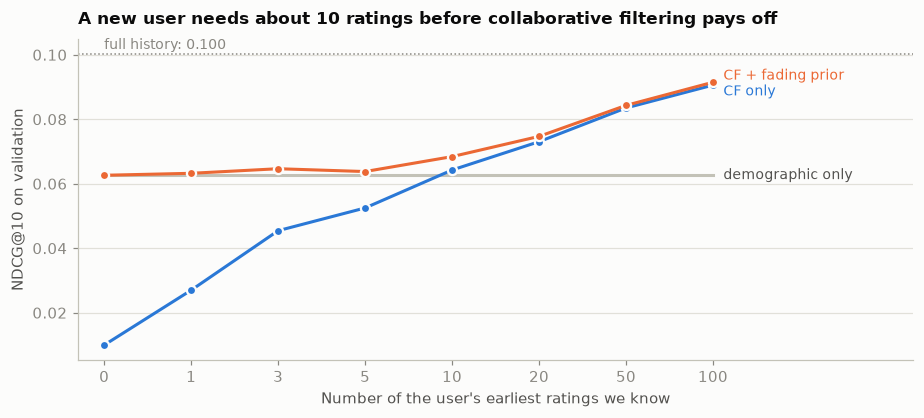

,known ratings,demographic only,CF only,CF + fading prior (tau=5),margin of error
0,0,0.063,0.010,0.063,0.003
1,1,0.063,0.027,0.063,0.003
2,3,0.063,0.045,0.065,0.003
3,5,0.063,0.052,0.064,0.003
4,10,0.063,0.064,0.068,0.003
5,20,0.063,0.073,0.075,0.004
6,50,0.063,0.084,0.084,0.004
7,100,0.063,0.091,0.091,0.004


In [51]:
moe = lambda a: 1.96 * a.std(ddof=1) / np.sqrt(len(a))
curve = pd.DataFrame({"known ratings": k_grid,
                      "demographic only": demo_per_user.mean(),
                      "CF only": [cf[k].mean() for k in k_grid],
                      f"CF + fading prior (tau={best_tau})": [rule[best_tau][k].mean() for k in k_grid],
                      "margin of error": [moe(rule[best_tau][k]) for k in k_grid]})
full_history = PER_USER[(HYBRID, "val")]["ndcg"].mean()           # the Step 7 hybrid with the whole training history

fig, ax = plt.subplots(figsize=(8.5, 3.9))
xx = np.arange(len(k_grid))
ax.axhline(full_history, color=MUTED, lw=1, ls=":")
ax.text(0, full_history + 0.0015, f"full history: {full_history:.3f}", color=MUTED, fontsize=9)
ax.plot(xx, curve["demographic only"], color=GRAY, lw=2)
ax.plot(xx, curve["CF only"], color=BLUE, lw=2, marker="o", ms=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.plot(xx, curve.iloc[:, 3], color=ORANGE, lw=2, marker="o", ms=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.text(xx[-1] + 0.12, curve["demographic only"].iloc[-1], "demographic only", color=INK2, fontsize=9, va="center")
ax.text(xx[-1] + 0.12, curve["CF only"].iloc[-1] - 0.002, "CF only", color=BLUE, fontsize=9, va="center")
ax.text(xx[-1] + 0.12, curve.iloc[:, 3].iloc[-1] + 0.002, "CF + fading prior", color=ORANGE, fontsize=9, va="center")
ax.set_xticks(xx, [str(k) for k in k_grid]); ax.set_xlim(-0.3, len(k_grid) + 1.3)
ax.set(title="A new user needs about 10 ratings before collaborative filtering pays off",
       xlabel="Number of the user's earliest ratings we know", ylabel="NDCG@10 on validation")
only_grid(ax, "y")
plt.tight_layout(); plt.show()
curve.round(4)

In [52]:
liked_any = liked_train | rel_val                                 # who liked what, in the train + val period
n_seen_any = (seen_train | seen_val).sum(axis=0)
eligible = np.flatnonzero(n_seen_any >= 30)                       # enough ratings to measure who would have liked the movie
folds = np.array_split(np.random.default_rng(SEED).permutation(eligible), 5)   # each movie is "new" in exactly one fold
print(f"{len(eligible):,} eligible movies, {len(folds[0])} hidden per fold")

X_gd = item_matrix(1, 0.5, 0, use_idf=True)                       # genres (idf) + decade
X_gdt = item_matrix(1, 0.5, 0.5, use_idf=True)                    # + title words
def ridge_map(X, warm, Y, lam):
    """Learn a linear map from content features to ALS movie vectors, using only movies that HAVE ratings."""
    F = np.hstack([X[warm], np.ones((len(warm), 1), np.float32)]).astype(np.float64)
    return np.linalg.solve(F.T @ F + lam * np.eye(F.shape[1]), F.T @ Y[warm])

def cold_ndcg(S, cold, users):
    recs = np.argsort(-S[users], axis=1, kind="stable")[:, :K]
    return ranking_metrics(recs, liked_any[:, cold][users], K)["ndcg"].mean()

ridge_grid = [0.3, 1, 3, 10]
fold_rows = []
for f, cold in enumerate(folds):
    cold = np.sort(cold); warm = np.setdiff1d(np.arange(n_items), cold)
    drop = np.isin(ic, cold)                                      # remove EVERY training rating of the hidden movies
    w_ = np.where(rt >= 4, 15.0, np.where(rt <= 2, 5.0, 0.0)) * ~drop
    conf = csr_matrix((w_[w_ > 0], (ur[w_ > 0], ic[w_ > 0])), shape=(n_users, n_items))
    liked_kept = (rt >= 4) & ~drop
    target = csr_matrix((16.0 * np.ones(liked_kept.sum()), (ur[liked_kept], ic[liked_kept])), shape=(n_users, n_items))
    X_f, Y_f, _ = als_implicit(conf, target, reg=100.0, eval_every=100)                 # ALS that has never seen the hidden movies
    users = np.flatnonzero(liked_any[:, cold].any(axis=1))        # users who liked at least one hidden movie
    taste = liked_train.astype(np.float32).copy(); taste[:, cold] = 0                  # a user's profile uses visible movies only
    row = {"random": cold_ndcg(np.random.default_rng(f).random((n_users, len(cold))), cold, users),
           "content similarity (genres + decade)": cold_ndcg(normalize(taste @ X_gd) @ X_gd[cold].T, cold, users)}
    for name, X in [("genres + decade", X_gd), ("genres + decade + title", X_gdt)]:
        for lam in ridge_grid:
            Y_hat = np.hstack([X[cold], np.ones((len(cold), 1), np.float32)]) @ ridge_map(X, warm, Y_f, lam)
            row[f"content -> ALS vector, {name}, ridge={lam}"] = cold_ndcg(X_f @ Y_hat.T, cold, users)
    row["popularity (impossible for a new movie)"] = cold_ndcg(
        np.broadcast_to(n_seen_any[cold].astype(float), (n_users, len(cold))), cold, users)
    fold_rows.append(row); print(f"fold {f + 1}/5 done", flush=True)

cold_res = pd.DataFrame(fold_rows)
cold_summary = pd.DataFrame({"mean NDCG@10": cold_res.mean(), "sd over folds": cold_res.std()}).round(4)
cold_summary

2,641 eligible movies, 529 hidden per fold
fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done


,mean NDCG@10,sd over folds
random,0.033,0.002
content similarity (genres + decade),0.112,0.010
"content -> ALS vector, genres + decade, ridge=0.3",0.196,0.003
"content -> ALS vector, genres + decade, ridge=1",0.196,0.004
"content -> ALS vector, genres + decade, ridge=3",0.194,0.005
"content -> ALS vector, genres + decade, ridge=10",0.190,0.009
"content -> ALS vector, genres + decade + title, ridge=0.3",0.225,0.024
"content -> ALS vector, genres + decade + title, ridge=1",0.228,0.017
"content -> ALS vector, genres + decade + title, ridge=3",0.214,0.010
"content -> ALS vector, genres + decade + title, ridge=10",0.196,0.010


best content -> vector model: content -> ALS vector, genres + decade + title, ridge=1


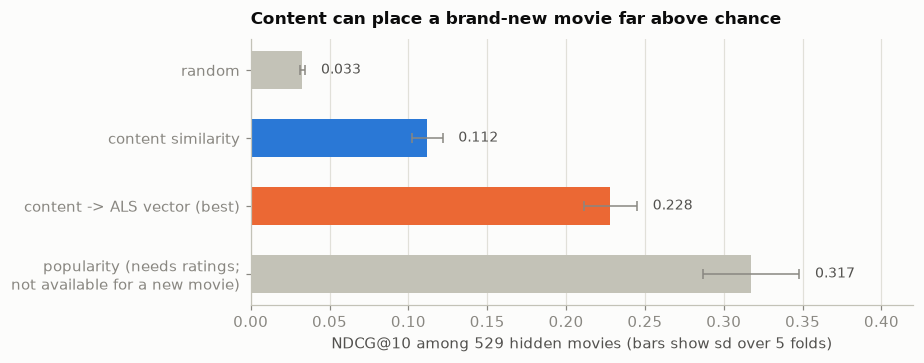

In [53]:
content_models = [c for c in cold_res.columns if c.startswith("content ->")]
best_cold = max(content_models, key=lambda c: cold_res[c].mean())          # chosen by the mean over the 5 folds
print("best content -> vector model:", best_cold)
show = ["random", "content similarity (genres + decade)", best_cold, "popularity (impossible for a new movie)"]
labels = ["random", "content similarity", "content -> ALS vector (best)", "popularity (needs ratings;\nnot available for a new movie)"]
means, sds = cold_res[show].mean().to_numpy(), cold_res[show].std().to_numpy()

fig, ax = plt.subplots(figsize=(8.5, 3.4))
yy = np.arange(len(show))[::-1]
ax.barh(yy, means, xerr=sds, height=0.55, color=[GRAY, BLUE, ORANGE, GRAY], error_kw=dict(ecolor=MUTED, lw=1, capsize=3))
for y_, v, sd in zip(yy, means, sds):
    ax.text(v + sd + 0.01, y_, f"{v:.3f}", va="center", color=INK2, fontsize=9)
ax.set_yticks(yy, labels)
ax.set(title="Content can place a brand-new movie far above chance", xlabel=f"NDCG@10 among {len(folds[0])} hidden movies (bars show sd over 5 folds)", xlim=(0, 0.42))
only_grid(ax, "x")
plt.tight_layout(); plt.show()

## 9. Error analysis, explanations, and fixing popularity bias

A single NDCG number hides who the model fails and what it recommends. For the hybrid on the validation users I ask:
1. What happens to the 10 slots of every list? (Hit, rated but not liked, or never rated.)
2. Which kinds of users are served well and which are not?
3. Which kinds of *movies* are served? (By popularity and by genre.)
4. Can every recommendation come with a reason, and is the reason faithful?
5. If the model over-recommends popular movies, can a simple penalty fix that without hurting accuracy?

Everything here uses the validation split. The test split is still untouched.

In [54]:
rows = EVAL_ROWS["val"]
seen_rows = PROTOCOL["val"]["exclude"][rows]
def topk_chunked(S, seen, k=K, chunk=1000):
    """Top-k movies per user (same stable tie rule as before), 1,000 users at a time to keep memory low."""
    out = []
    for a in range(0, len(S), chunk):
        s = np.where(seen[a:a + chunk], -np.inf, S[a:a + chunk])
        out.append(np.argsort(-s, axis=1, kind="stable")[:, :k])
    return np.vstack(out)

recs_h = topk_chunked(S_hybrid[rows], seen_rows)                       # the hybrid's lists for the 5,819 validation users
hit = np.take_along_axis(rel_val[rows], recs_h, axis=1)                # liked later
rated = np.take_along_axis(seen_val[rows], recs_h, axis=1)             # rated at all in the validation window
slot_kind = np.where(hit, "liked later (hit)", np.where(rated, "rated later but not liked", "never rated in the validation window"))
print(pd.Series(slot_kind.ravel()).value_counts(normalize).map("{:.1%}".format).to_string())
print(f"\nusers with no hit in their top 10: {(~hit.any(axis=1)).mean():.1%}")

never rated in the validation window    91.5%
liked later (hit)                        6.9%
rated later but not liked                1.6%

users with no hit in their top 10: 57.1%


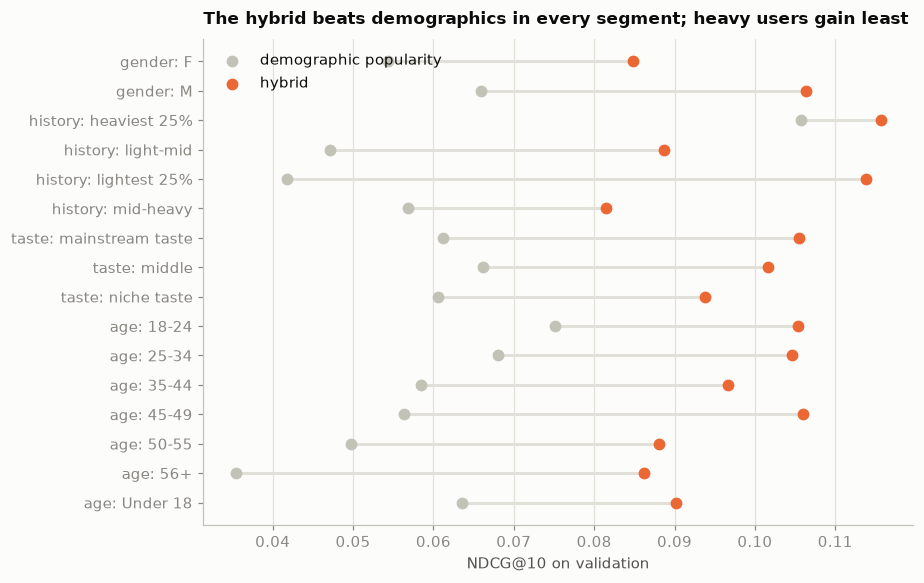

,value,users,demographic,hybrid,group,gain
0,F,1647,0.054,0.085,gender,0.030
1,M,4172,0.066,0.106,gender,0.041
2,heaviest 25%,1443,0.106,0.116,history,0.010
3,light-mid,1376,0.047,0.089,history,0.042
4,lightest 25%,1556,0.042,0.114,history,0.072
5,mid-heavy,1444,0.057,0.082,history,0.025
6,mainstream taste,1940,0.061,0.105,taste,0.044
7,middle,1939,0.066,0.102,taste,0.035
8,niche taste,1940,0.060,0.094,taste,0.033
9,18-24,1053,0.075,0.105,age,0.030


In [55]:
u_rows = u_info.iloc[rows]                                             # gender / age of the validation users (u_info comes from Step 4)
history = seen_train.sum(axis=1)[rows]
pop_pct = pd.Series(train_n).rank(pct=True).to_numpy()                  # 1 = the most-rated movie
mainstream = (liked_train[rows] @ pop_pct) / np.maximum(liked_train[rows].sum(axis=1), 1)   # how popular is the typical movie this user likes?
profile = pd.DataFrame({
    "gender": u_rows.gender.to_numpy(), "age": u_rows.age.to_numpy(),
    "history": pd.qcut(history, 4, labels=["lightest 25%", "light-mid", "mid-heavy", "heaviest 25%"]).astype(str),
    "taste": pd.qcut(mainstream, 3, labels=["niche taste", "middle", "mainstream taste"]).astype(str),
    "hybrid": PER_USER[(HYBRID, "val")]["ndcg"], "demographic": PER_USER[(names["demo"], "val")]["ndcg"]})
seg = pd.concat([profile.groupby(c).agg(users=("hybrid", "size"), demographic=("demographic", "mean"), hybrid=("hybrid", "mean"))
                 .assign(group=c).reset_index(names="value") for c in ["gender", "history", "taste", "age"]], ignore_index=True)
seg["gain"] = seg.hybrid - seg.demographic

fig, ax = plt.subplots(figsize=(8.5, 5.4))
yy = np.arange(len(seg))[::-1]
ax.hlines(yy, seg.demographic, seg.hybrid, color=GRID, lw=2)
ax.scatter(seg.demographic, yy, color=GRAY, s=45, zorder=3, label="demographic popularity")
ax.scatter(seg.hybrid, yy, color=ORANGE, s=45, zorder=3, label="hybrid")
ax.set_yticks(yy, seg.group + ": " + seg.value)
ax.set(title="The hybrid beats demographics in every segment; heavy users gain least", xlabel="NDCG@10 on validation")
ax.legend(loc="upper left")
only_grid(ax, "x")
plt.tight_layout(); plt.show()
seg.round(4)

                 share of held-out likes  share of recommended slots  recall of those likes
least rated 20%                    0.005                       0.000                  0.000
2nd                                0.026                       0.000                  0.000
3rd                                0.076                       0.000                  0.000
4th                                0.209                       0.005                  0.002
most rated 20%                     0.684                       0.995                  0.108


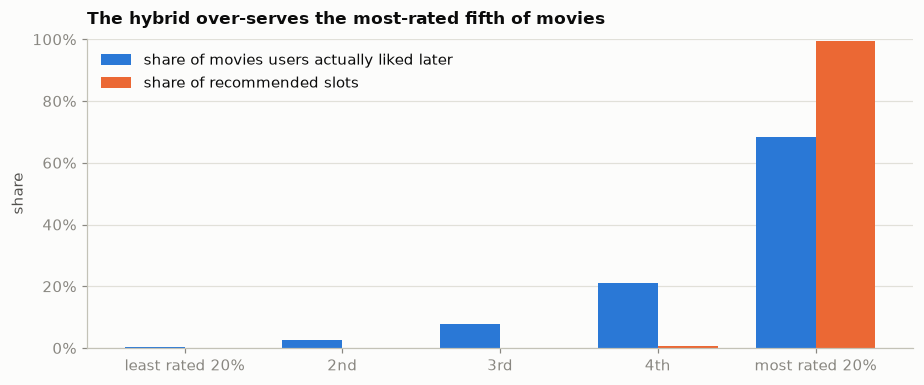


recall of held-out liked movies by genre (lowest 5 | highest 5):
Documentary     0.8%
Western         3.1%
Musical         3.8%
Horror          4.1%
Children's      5.2%
Film-Noir      13.8%
War            14.6%
Action         15.6%
Adventure      16.8%
Sci-Fi         18.4%

movies shown most often:
                                                movie  lists containing it  hits
Star Wars: Episode V - The Empire Strikes Back (1980)                 1453    92
                           Saving Private Ryan (1998)                 1262    72
                       Raiders of the Lost Ark (1981)                 1204    98
                                         Fargo (1996)                 1197    79
                     Silence of the Lambs, The (1991)                 1193    69
            Star Wars: Episode IV - A New Hope (1977)                 1104    81
                           Princess Bride, The (1987)                 1044    49
    Star Wars: Episode VI - Return of the Jedi (19

In [56]:
pop_quintile = pd.qcut(pd.Series(train_n).rank(method="first"), 5, labels=False).to_numpy()   # 0 = least-rated fifth of movies, 4 = most-rated
hit_items = recs_h[hit]                                                  # the movie in every hit slot
rel_per_item = rel_val[rows].sum(axis=0)                                 # how many validation users liked each movie
rec_per_item = np.bincount(recs_h.ravel(), minlength=n_items)
hit_per_item = np.bincount(hit_items, minlength=n_items)
by_q = pd.DataFrame({
    "share of held-out likes": np.bincount(pop_quintile, weights=rel_per_item) / rel_per_item.sum(),
    "share of recommended slots": np.bincount(pop_quintile, weights=rec_per_item) / rec_per_item.sum(),
    "recall of those likes": np.bincount(pop_quintile, weights=hit_per_item) / np.bincount(pop_quintile, weights=rel_per_item)},
    index=["least rated 20%", "2nd", "3rd", "4th", "most rated 20%"])
print(by_q.round(3).to_string())

fig, ax = plt.subplots(figsize=(8.5, 3.6))
xx = np.arange(5); w = 0.38
ax.bar(xx - w / 2, by_q["share of held-out likes"], w, color=BLUE, label="share of movies users actually liked later")
ax.bar(xx + w / 2, by_q["share of recommended slots"], w, color=ORANGE, label="share of recommended slots")
ax.set_xticks(xx, by_q.index)
ax.set(title="The hybrid over-serves the most-rated fifth of movies", ylabel="share", ylim=(0, 1.0))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(loc="upper left")
only_grid(ax, "y")
plt.tight_layout(); plt.show()

g_rel, g_hit = genre_mat.T @ rel_per_item, genre_mat.T @ hit_per_item
by_genre = pd.Series(g_hit / np.maximum(g_rel, 1), index=genre_names).sort_values()
print("\nrecall of held-out liked movies by genre (lowest 5 | highest 5):")
print(pd.concat([by_genre.head(5), by_genre.tail(5)]).map("{:.1%}".format).to_string())

top_rec = np.argsort(-rec_per_item)[:8]
print("\nmovies shown most often:")
print(pd.DataFrame({"movie": [titles[item_ids[j]] for j in top_rec], "lists containing it": rec_per_item[top_rec],
                    "hits": hit_per_item[top_rec]}).to_string(index=False))
print(f"\nthe 10 most-shown movies fill {np.sort(rec_per_item)[-10:].sum() / rec_per_item.sum():.1%} of all slots; "
      f"{(rec_per_item > 0).mean():.1%} of the catalogue is ever shown")
missed = np.argsort(-(rel_per_item * (rec_per_item == 0)))[:6]
print("\nmost-liked movies that were NEVER recommended to anyone:")
print(pd.DataFrame({"movie": [titles[item_ids[j]] for j in missed], "users who liked it later": rel_per_item[missed],
                    "ratings in training": train_n[missed]}).to_string(index=False))

In [57]:
def explain_hybrid(user_row, item_col, top=2):
    """The movies this user liked that contribute most to the item-kNN part of the score, and how much of that part they explain."""
    contrib = R_lik[user_row] * sim_knn[:, item_col]
    order = np.argsort(-contrib)[:top]
    share = contrib[order].sum() / max(contrib.sum(), 1e-9)
    return ", ".join(titles[item_ids[m]] for m in order if contrib[m] > 0), share

def recs_table(user_row, n=5):
    pos = np.flatnonzero(rows == user_row)[0]
    out = []
    for j in recs_h[pos][:n]:
        because, share = explain_hybrid(user_row, j)
        out.append({"recommended": titles[item_ids[j]], "because you liked": because, "explains": f"{share:.0%}",
                    "liked later?": "yes" if rel_val[user_row, j] else ("rated, no" if seen_val[user_row, j] else "not rated")})
    return pd.DataFrame(out)

hist_all = seen_train.sum(axis=1)
def typical(bucket):
    idx = rows[(profile.history == bucket).to_numpy()]
    return idx[np.argmin(np.abs(hist_all[idx] - np.median(hist_all[idx])))]
for label, ur_ in [("typical user (as in Steps 5 and 6)", pick), ("light-history user", typical("lightest 25%")), ("heavy-history user", typical("heaviest 25%"))]:
    print(f"\n{label}: user {user_ids[ur_]} with {hist_all[ur_]} training ratings")
    print(recs_table(ur_).to_string(index=False))


typical user (as in Steps 5 and 6): user 38 with 70 training ratings
                   recommended                                               because you liked explains liked later?
           Pretty Woman (1990)                       Sleepless in Seattle (1993), Ghost (1990)       9%    not rated
American President, The (1995) Sleepless in Seattle (1993), Four Weddings and a Funeral (1994)       8%    not rated
          Groundhog Day (1993)                     Shakespeare in Love (1998), Clueless (1995)       9%    not rated
        You've Got Mail (1998)     Sleepless in Seattle (1993), While You Were Sleeping (1995)      10%    not rated
     As Good As It Gets (1997)                            Forrest Gump (1994), Clueless (1995)       8%    not rated

light-history user: user 144 with 23 training ratings
                     recommended                               because you liked explains liked later?
      Saving Private Ryan (1998)       Schindler's List (1993), Gladia

In [58]:
def zrow(v, unseen):
    mu, sd = v[unseen].mean(), v[unseen].std() + 1e-9
    return (v - mu) / sd

rng = np.random.default_rng(SEED)
sample = rng.choice(rows, 600, replace=False)
outcome = {"cited movie removed": [], "random liked movie removed": []}
for u in sample:
    unseen = ~seen_train[u]
    s_knn, z_als = S_knn[u].copy(), zrow(S_als[u], unseen)                # the ALS part is held fixed (see the note below)
    base = zrow(s_knn, unseen) + best_w * z_als
    base[~unseen] = -np.inf
    top = np.argsort(-base, kind="stable")[:K]
    liked_u = np.flatnonzero(R_lik[u])
    for j in top:
        cited = liked_u[np.argmax(sim_knn[liked_u, j])]
        other = rng.choice(liked_u[liked_u != cited]) if len(liked_u) > 1 else cited
        for name, m in [("cited movie removed", cited), ("random liked movie removed", other)]:
            alt = zrow(s_knn - sim_knn[m], unseen) + best_w * z_als
            alt[~unseen] = -np.inf
            outcome[name].append((alt > alt[j]).sum() >= K)                # True = the item fell out of the top 10
print("share of recommendations that LEAVE the top 10 when one liked movie is removed from the profile:")
print(pd.Series({k: np.mean(v) for k, v in outcome.items()}).map("{:.1%}".format).to_string())

share of recommendations that LEAVE the top 10 when one liked movie is removed from the profile:
cited movie removed           9.2%
random liked movie removed    1.9%


largest penalty whose accuracy loss is within noise: gamma = 1.0


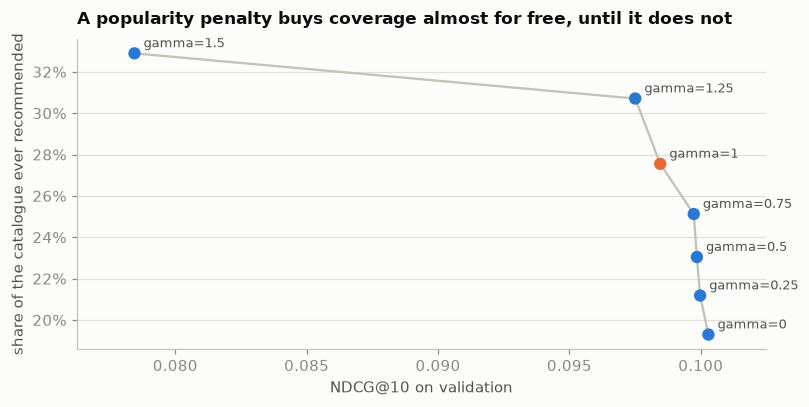

NDCG@10  hybrid + popularity penalty (gamma=1)  minus  hybrid: item-kNN + 0.3 x ALS: -0.0018 +/- 0.0019  -> within noise


,ndcg@10,precision@10,coverage,novelty,diversity,ndcg change,margin of error
gamma,,,,,,,
0.000,0.100,0.070,0.193,2.157,0.729,0.000,0.000
0.250,0.100,0.069,0.212,2.233,0.721,-0.000,0.001
0.500,0.100,0.068,0.230,2.318,0.713,-0.000,0.001
0.750,0.100,0.068,0.251,2.416,0.703,-0.001,0.002
1.000,0.099,0.067,0.276,2.527,0.691,-0.002,0.002
1.250,0.098,0.065,0.307,2.661,0.679,-0.003,0.002
1.500,0.078,0.044,0.329,5.487,0.672,-0.022,0.003


In [59]:
log_pop = np.log(train_n + 1.0)
log_pop_z = ((log_pop - log_pop.mean()) / log_pop.std()).astype(np.float32)      # per movie: how popular it is, standardised

gamma_grid = [0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]
H_rows, per_user, trade = S_hybrid[rows], {}, []
for gam in gamma_grid:
    recs = topk_chunked(H_rows - gam * log_pop_z[None, :], seen_rows)            # score = hybrid score - gamma * popularity
    m = ranking_metrics(recs, rel_val[rows], K)
    per_user[gam] = m["ndcg"]
    trade.append({"gamma": gam, "ndcg@10": m["ndcg"].mean(), "precision@10": m["precision"].mean(),
                  "coverage": catalogue_coverage(recs, n_items), "novelty": novelty(recs, item_pop_prob),
                  "diversity": intra_list_diversity(recs, genre_mat)})
trade = pd.DataFrame(trade).set_index("gamma")
loss = {g_: per_user[g_] - per_user[0] for g_ in gamma_grid}                      # paired, per user
trade["ndcg change"] = [loss[g_].mean() for g_ in gamma_grid]
trade["margin of error"] = [1.96 * loss[g_].std(ddof=1) / np.sqrt(len(rows)) if g_ else 0.0 for g_ in gamma_grid]
safe = [g_ for g_ in gamma_grid if trade.loc[g_, "ndcg change"] > -trade.loc[g_, "margin of error"]]   # accuracy loss not distinguishable from noise
best_gamma = max(safe)
print("largest penalty whose accuracy loss is within noise: gamma =", best_gamma)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(trade["ndcg@10"], trade["coverage"], color=GRAY, lw=1.5)
ax.scatter(trade["ndcg@10"], trade["coverage"], color=[ORANGE if g_ == best_gamma else BLUE for g_ in trade.index], s=50, zorder=3)
for g_, r in trade.iterrows():
    ax.annotate(f"gamma={g_:g}", (r["ndcg@10"], r["coverage"]), textcoords="offset points", xytext=(6, 4), fontsize=8.5, color=INK2)
ax.set(title="A popularity penalty buys coverage almost for free, until it does not",
       xlabel="NDCG@10 on validation", ylabel="share of the catalogue ever recommended")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.margins(x=0.1)
only_grid(ax, "y")
plt.tight_layout(); plt.show()

FINAL = f"hybrid + popularity penalty (gamma={best_gamma:g})"
S_final = S_hybrid - best_gamma * log_pop_z[None, :]
_ = evaluate_model(FINAL, S_final, "val")
d, moe = paired_diff(FINAL, HYBRID)
print(f"NDCG@10  {FINAL}  minus  {HYBRID}: {d:+.4f} +/- {moe:.4f}  -> {'real' if abs(d) > moe else 'within noise'}")
trade.round(4)

## 10. Demo app

The models are packaged in `src/recsys.py` and served by a Streamlit app (`app/streamlit_app.py`). Three checks before calling it done:
1. **Does the app reproduce the notebook?** Fit the app's code on the training split and compare its lists with the final model's lists for the same users.
2. **Does "like X but …" do what it says?** Measure, over 150 well-known movies, how the top 10 shift for each modifier and what it costs in closeness to the original movie.
3. **Screenshots** of the running app.

"Lighter", "darker" and friends are rule-based: they use genres and release year only, and the app says which words it understood and which it ignored. There is no LLM in the loop.

In [60]:
import sys, importlib
ROOT = Path.cwd()
while not (ROOT / "src" / "recsys.py").exists() and ROOT != ROOT.parent:      # walk up from the notebook's folder until we find the repo root
    ROOT = ROOT.parent
assert (ROOT / "src" / "recsys.py").exists(), (
    f"src/recsys.py not found above {Path.cwd()}. Put the unzipped 'src' folder next to 'notebooks/' in the repo root.")
sys.path.insert(0, str(ROOT))
importlib.invalidate_caches()
from src.recsys import Recommender, build_artifacts
print("repo root:", ROOT)

build_artifacts(DATA_DIR, ROOT / "artifacts_train", train_only=True, verbose=False)   # same models, fitted on the training split only
app_check = Recommender(ROOT / "artifacts_train")

repo root: c:\Users\Sanyam\projects\movie-recommendation-engine


In [61]:
import os
from pathlib import Path
print("notebook working folder:", Path.cwd())
for base in [Path.cwd(), Path.cwd().parent]:
    print(f"\ncontents of {base}:")
    print("  ", sorted(p.name for p in base.iterdir() if p.name not in {".venv", ".git"})[:40])
print("\nevery recsys.py found under the repo (skipping .venv and .git):")
for root, dirs, files in os.walk(Path.cwd().parent):
    dirs[:] = [d for d in dirs if d not in {".venv", ".git", "node_modules"}]
    if "recsys.py" in files:
        print("  ", Path(root) / "recsys.py")

notebook working folder: c:\Users\Sanyam\projects\movie-recommendation-engine\notebooks

contents of c:\Users\Sanyam\projects\movie-recommendation-engine\notebooks:
   ['movie_recommendation_engine.ipynb']

contents of c:\Users\Sanyam\projects\movie-recommendation-engine:
   ['.gitignore', '.pytest_cache', 'app', 'artifacts', 'artifacts_train', 'data', 'notebooks', 'pytest.ini', 'reports', 'src', 'tests', 'tools']

every recsys.py found under the repo (skipping .venv and .git):
   c:\Users\Sanyam\projects\movie-recommendation-engine\src\recsys.py


### What the hybrid tells us
- Rescaling scores to z-scores does not change any single model's ranking (the component scores match the earlier ones), so the blend is fair.
- Adding ALS to item-kNN helps up to a weight of 0.3 (NDCG@10 0.0935 → 0.1003), then falls again (0.0947 at 1.5). The best weight is 0.3 on both random halves of the validation users, so it is not a lucky split.
- Adding SVD, content, popularity or demographic scores on top gave no further gain (all at or below 0.099 even at the smallest weight, and clearly worse at larger ones).
- Paired tests: the hybrid beats item-kNN by +0.0068 ± 0.0024, ALS by +0.0113 ± 0.0024 and demographic popularity by +0.0377 ± 0.0042. All are real.
- The gain is largest for users with little history (lightest quartile: 0.114 vs 0.098 for kNN alone) and smallest for heavy users, where all models are close (0.116 vs 0.112).

In [62]:
import sys
ROOT = Path("..").resolve()                                           # the repository root (this notebook lives in notebooks/)
sys.path.insert(0, str(ROOT))
from src.recsys import Recommender, build_artifacts

build_artifacts(DATA_DIR, ROOT / "artifacts_train", train_only=True, verbose=False)   # same models, fitted on the training split only
app_check = Recommender(ROOT / "artifacts_train")

In [63]:
check_rows = rows[::3]                                                # every third validation user (about 1,940 users)
by_user = {u: d for u, d in train.groupby("user_id")}
app_lists = []
for r in check_rows:
    d = by_user[user_ids[r]]
    out = app_check.recommend(dict(zip(d.movie_id, d.rating)), u_info.iloc[r].gender, int(u_info.iloc[r].age_code), n=K)
    app_lists.append([app_check.col[m] for m in out.movie_id])
app_ndcg = ranking_metrics(np.array(app_lists), rel_val[check_rows], K)["ndcg"]
nb_ndcg = PER_USER[(FINAL, "val")]["ndcg"][::3]                       # the notebook's own per-user scores for the same users
diff = app_ndcg - nb_ndcg
print(f"item-kNN matrix identical: {np.allclose(app_check.sim, sim_knn, atol=1e-6)} | ALS movie vectors identical: {np.allclose(app_check.Y, Y_als, atol=1e-4)}")
print(f"NDCG@10 on {len(check_rows):,} validation users: notebook {nb_ndcg.mean():.4f} | app {app_ndcg.mean():.4f} | "
      f"difference {diff.mean():+.4f} +/- {1.96 * diff.std(ddof=1) / np.sqrt(len(diff)):.4f}")

item-kNN matrix identical: True | ALS movie vectors identical: True
NDCG@10 on 1,940 validation users: notebook 0.0966 | app 0.0955 | difference -0.0011 +/- 0.0032


In [64]:
build_artifacts(DATA_DIR, ROOT / "artifacts", verbose=False)         # final app model: fitted on all ratings
app = Recommender(ROOT / "artifacts")
lightness = app.lightness()
anchors = np.random.default_rng(SEED).choice(np.flatnonzero(app.n_pop >= 300), 150, replace=False)   # 150 well-known movies as starting points

def modifier_effect(text):
    stats = []
    for a in anchors:
        df, _, _ = app.similar(app.item_ids[a], text)
        cols = [app.col[m] for m in df.movie_id]
        stats.append((lightness[cols].mean(), np.nanmean(app.years[cols]), np.log(app.n_pop[cols]).mean(), df["audience similarity rank"].mean()))
    return np.mean(stats, axis=0)

texts = ["", "lighter", "darker", "funnier", "scarier", "newer", "older", "more obscure"]
effect = pd.DataFrame([modifier_effect(t) for t in texts], index=[t or "(no modifier)" for t in texts],
                      columns=["mean lightness (-1..1)", "mean release year", "mean log-popularity", "mean audience-similarity rank"])
effect.round(2)

,mean lightness (-1..1),mean release year,mean log-popularity,mean audience-similarity rank
(no modifier),0.060,"1,987.890",6.730,5.500
lighter,0.410,"1,987.960",6.750,10.380
darker,-0.260,"1,987.910",6.730,9.400
funnier,0.260,"1,988.350",6.770,9.050
scarier,-0.100,"1,988.050",6.760,8.890
newer,0.070,"1,991.220",6.760,8.110
older,0.060,"1,983.390",6.730,10.140
more obscure,0.050,"1,987.800",6.620,5.900


In [65]:
for title, text in [("Alien (1979)", "lighter"), ("Matrix, The (1999)", "funnier and more obscure"), ("Toy Story (1995)", "darker")]:
    df, understood, ignored = app.similar(app.search(title, 1)[0][0], text)
    print(f"\n{title} but '{text}'   (understood: {[u.split(' (')[0] for u in understood]})")
    print(df[["title", "genres", "audience similarity rank"]].head(5).to_string(index=False))


Alien (1979) but 'lighter'   (understood: ['lighter'])
                                                title                            genres  audience similarity rank
            Star Wars: Episode IV - A New Hope (1977)   Action|Adventure|Fantasy|Sci-Fi                         3
                                        Aliens (1986)        Action|Sci-Fi|Thriller|War                         1
                               Terminator, The (1984)            Action|Sci-Fi|Thriller                         2
                            Back to the Future (1985)                     Comedy|Sci-Fi                        15
Star Wars: Episode V - The Empire Strikes Back (1980) Action|Adventure|Drama|Sci-Fi|War                         4

Matrix, The (1999) but 'funnier and more obscure'   (understood: ['more obscure', 'more Comedy'])
                            title                           genres  audience similarity rank
              Men in Black (1997)   Action|Adventure|Comedy|Sci-Fi  

In [66]:
from IPython.display import Image, display
for name in ["app_recommend.png", "app_like_but.png"]:
    path = ROOT / "reports" / "figures" / name
    display(Image(filename=path, width=900)) if path.exists() else print(f"missing {path}: take the screenshot and save it there")

missing C:\Users\Sanyam\projects\movie-recommendation-engine\reports\figures\app_recommend.png: take the screenshot and save it there
missing C:\Users\Sanyam\projects\movie-recommendation-engine\reports\figures\app_like_but.png: take the screenshot and save it there


### What the demo checks tell us
The app is the same model: identical kNN matrix and ALS vectors, and on 1,940 validation users NDCG@10 is 0.0955 (app) vs 0.0966 (notebook), a difference of −0.0011 ± 0.0032. "Like X but…" works for tone and era (lighter raises mean lightness from 0.06 to 0.41; newer shifts release year by +3.3 years) and weakly for obscurity (mean log-popularity 6.73 → 6.62), because the 150 nearest neighbours are already mostly well known. Each modifier costs closeness to the original movie (mean similarity rank 5.5 → 8–10). The data ends in 2000, so "more recent" has limited room.

## 11. Final evaluation on the untouched test set

Everything so far was tuned on the validation split. Now I use the test split exactly once:
- every model is **refit on train + validation** (each user's oldest 80% of ratings) with **frozen** hyper-parameters (k=30 for SVD, ALS weight 0.3, content prior 1, popularity penalty gamma 1);
- seen movies (train + validation) are excluded from the lists, and the newest 20% of each user's ratings are the answer key;
- the cold-start rule (demographic prior fading with 1 / (1 + k/5)) is checked on test users **without re-tuning**.

Numbers are higher than on validation for every model, since test users have more history in training. So I compare models with each other, not splits with each other.

In [67]:
import gc
for name_ in ["S_knn", "S_svd", "S_als", "S_hybrid", "S_final", "C_content", "P_content", "Z", "extra", "base", "W_cent", "seg_scores"]:
    globals().pop(name_, None)                                       # validation-time score matrices (about 90 MB each) are no longer needed
gc.collect()

trainval = pd.concat([train, val])                                   # each user's oldest 80% of ratings
ur_tv = u_pos.loc[trainval.user_id].to_numpy(); ic_tv = i_pos.loc[trainval.movie_id].to_numpy(); rt_tv = trainval.rating.to_numpy()
seen_tv, liked_tv = seen_train | seen_val, liked_train | rel_val
n_tv = seen_tv.sum(axis=0)                                           # popularity counts now include the validation period
exclude_test = PROTOCOL["test"]["exclude"]
assert (exclude_test == seen_tv).all() and len(trainval) + len(test) == len(ratings)
print(f"fit on {len(trainval):,} ratings, evaluate on {len(test):,} test ratings from {len(EVAL_ROWS['test']):,} users")
print("frozen from validation:", {"best_k": best_k, "best_w": best_w, "best_lam": best_lam, "best_gamma": best_gamma})

fit on 800,193 ratings, evaluate on 200,016 test ratings from 5,966 users
frozen from validation: {'best_k': 30, 'best_w': 0.3, 'best_lam': 1.0, 'best_gamma': 1.0}


### What cold start tells us
**New users.** A demographic list scores 0.063 whatever the user does. Collaborative filtering alone is nearly useless with no ratings (0.010) and passes the demographic list at about 10 ratings (0.064 vs 0.063). Blending in the demographic prior, faded as 1 / (1 + k/5), is at least as good at every k (0.065 at 3 ratings, 0.068 at 10, 0.075 at 20) and the two curves meet by 100 ratings. The gains over collaborative filtering alone are small (close to the ±0.003–0.004 margin) except at the very start, so this rule is mainly a safety net for the first few ratings.

**New movies.** Random scores 0.033 and genre/decade similarity 0.112. Learning to predict a movie's ALS vector from its genres, decade and title words reaches 0.228, so title words add about 0.03. Popularity (0.317) would do better, but it is impossible for a movie nobody has rated yet.

In [68]:
Rd_all, Rd_lik = seen_tv.astype(np.float32), liked_tv.astype(np.float32)
ev = lambda name, S: evaluate_model(name, S, "test")

_ = ev("random (floor)", np.random.default_rng(SEED).random((n_users, n_items)))
_ = ev("oracle (ceiling)", rel_test.astype(np.float32))
_ = ev("popularity: most rated", broadcast(n_tv))

seg_share_tv = np.zeros((n_users, n_items), dtype=np.float32)
for s in np.unique(segment):
    idx = np.flatnonzero(segment == s)
    seg_share_tv[idx] = liked_tv[idx].mean(axis=0)
_ = ev(names["demo"], seg_share_tv)

C_t = normalize(Rd_lik @ X_idf_dec) @ X_idf_dec.T                    # content similarity (genres + decade)
_ = ev(names["blend"], C_t + best_lam * (n_tv / n_tv.max()).astype(np.float32)); del C_t

sim_tv = item_similarity(Rd_all)
S_knn_t = Rd_lik @ sim_tv
_ = ev(names["knn"], S_knn_t)

_, _, Vt_tv = svds(csr_matrix(Rd_lik), k=best_k, random_state=SEED)
_ = ev(names["svd"], (Rd_lik @ Vt_tv.T) @ Vt_tv)

w_ = np.where(rt_tv >= 4, 15.0, np.where(rt_tv <= 2, 5.0, 0.0)); keep_ = w_ > 0
conf_tv = csr_matrix((w_[keep_], (ur_tv[keep_], ic_tv[keep_])), shape=(n_users, n_items))
pos_ = rt_tv >= 4
target_tv = csr_matrix((16.0 * np.ones(pos_.sum()), (ur_tv[pos_], ic_tv[pos_])), shape=(n_users, n_items))
X_tv, Y_tv, _ = als_implicit(conf_tv, target_tv, reg=100.0, eval_every=10 ** 6)       # never evaluates on validation
S_als_t = X_tv @ Y_tv.T
_ = ev(names["als"], S_als_t)

S_hyb_t = zscore_unseen(S_knn_t, seen_tv) + best_w * zscore_unseen(S_als_t, seen_tv)
_ = ev(HYBRID, S_hyb_t)
lp_t = np.log(n_tv + 1.0); lpz_t = ((lp_t - lp_t.mean()) / lp_t.std()).astype(np.float32)
_ = ev(FINAL, S_hyb_t - best_gamma * lpz_t[None, :])
del S_knn_t, S_als_t, S_hyb_t; gc.collect()

*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***


0

In [69]:
tbl_test = results_table("test").droplevel("split")
tbl_val = results_table("val").droplevel("split")
tbl_test, tbl_val = (t[~t.index.duplicated(keep="last")] for t in (tbl_test, tbl_val))   # a re-run cell logs a model twice; keep the latest
order = ["random (floor)", "oracle (ceiling)", "popularity: most rated", names["demo"], names["blend"],
         names["knn"], names["svd"], names["als"], HYBRID, FINAL]
cols = ["precision@10", "recall@10", "hit_rate@10", "ndcg@10", "ndcg_ci95", "coverage", "diversity", "novelty"]
print(tbl_test.loc[order, cols].round(4).to_string())
compare = pd.DataFrame({"val NDCG@10": tbl_val["ndcg@10"], "test NDCG@10": tbl_test["ndcg@10"]}).loc[order[2:]]
compare["change"] = compare["test NDCG@10"] - compare["val NDCG@10"]
compare.round(4)

                                              precision@10  recall@10  hit_rate@10  ndcg@10  ndcg_ci95  coverage  diversity  novelty
model                                                                                                                               
random (floor)                                       0.005      0.003        0.053    0.006      0.001     1.000      0.828    6.803
oracle (ceiling)                                     0.773      0.735        1.000    1.000      0.000     0.734      0.751    3.815
popularity: most rated                               0.080      0.047        0.389    0.091      0.004     0.032      0.742    1.499
popularity: by demographic group (alpha=0.0)         0.088      0.053        0.413    0.099      0.004     0.061      0.770    1.646
content + popularity prior (lambda=1)                0.077      0.061        0.443    0.093      0.004     0.138      0.647    1.920
item-kNN (cosine)                                    0.104      0.082

,val NDCG@10,test NDCG@10,change
model,,,
popularity: most rated,0.058,0.091,0.032
popularity: by demographic group (alpha=0.0),0.063,0.099,0.036
content + popularity prior (lambda=1),0.068,0.093,0.025
item-kNN (cosine),0.093,0.126,0.032
PureSVD (k=30),0.088,0.129,0.041
"ALS implicit (64 factors, reg=100)",0.089,0.126,0.037
hybrid: item-kNN + 0.3 x ALS,0.100,0.137,0.037
hybrid + popularity penalty (gamma=1),0.099,0.133,0.035


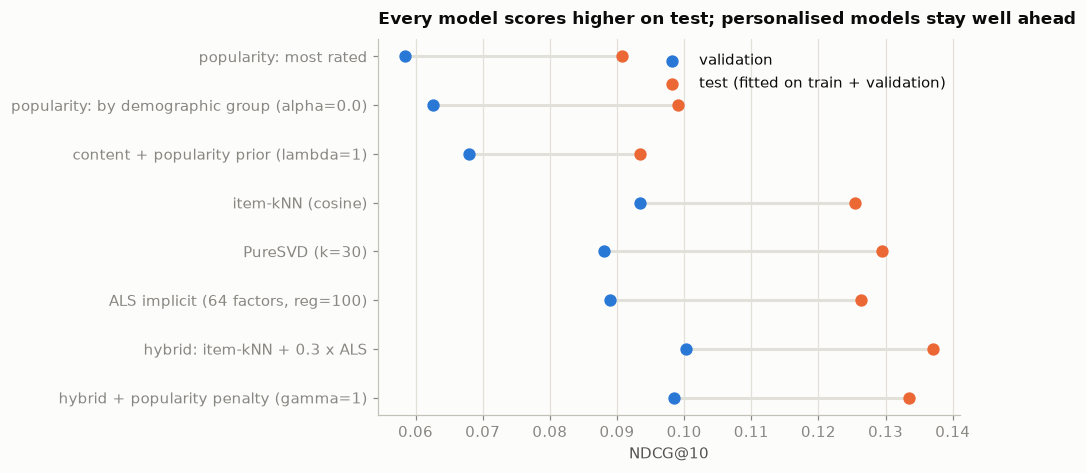

In [70]:
fig, ax = plt.subplots(figsize=(9, 4.4))
yy = np.arange(len(compare))[::-1]
ax.hlines(yy, compare["val NDCG@10"], compare["test NDCG@10"], color=GRID, lw=2)
ax.scatter(compare["val NDCG@10"], yy, color=BLUE, s=50, zorder=3, label="validation")
ax.scatter(compare["test NDCG@10"], yy, color=ORANGE, s=50, zorder=3, label="test (fitted on train + validation)")
ax.set_yticks(yy, compare.index)
ax.set(title="Every model scores higher on test; personalised models stay well ahead", xlabel="NDCG@10")
ax.legend(loc="upper right")
only_grid(ax, "x")
plt.tight_layout(); plt.show()

In [71]:
for a, b in [(names["knn"], names["demo"]), (HYBRID, names["knn"]), (FINAL, HYBRID), (FINAL, names["demo"]), (names["als"], names["svd"])]:
    d, moe = paired_diff(a, b, split="test")
    print(f"NDCG@10 (test)  {a}  minus  {b}: {d:+.4f} +/- {moe:.4f}  -> {'real' if abs(d) > moe else 'within noise'}")

NDCG@10 (test)  item-kNN (cosine)  minus  popularity: by demographic group (alpha=0.0): +0.0265 +/- 0.0041  -> real
NDCG@10 (test)  hybrid: item-kNN + 0.3 x ALS  minus  item-kNN (cosine): +0.0116 +/- 0.0024  -> real
NDCG@10 (test)  hybrid + popularity penalty (gamma=1)  minus  hybrid: item-kNN + 0.3 x ALS: -0.0037 +/- 0.0020  -> real
NDCG@10 (test)  hybrid + popularity penalty (gamma=1)  minus  popularity: by demographic group (alpha=0.0): +0.0344 +/- 0.0049  -> real
NDCG@10 (test)  ALS implicit (64 factors, reg=100)  minus  PureSVD (k=30): -0.0031 +/- 0.0028  -> real


In [72]:
rows_t = EVAL_ROWS["test"]
seen_rows_t, rel_rows_t = exclude_test[rows_t], rel_test[rows_t]
age_rank_t = trainval.groupby("user_id").cumcount().to_numpy()       # 0 = oldest rating (train rows come first, then validation rows)
row_of_t = pd.Series(np.arange(len(rows_t)), index=rows_t)
in_t = np.isin(ur_tv, rows_t)
YtY_t = Y_tv.T @ Y_tv + 100.0 * np.eye(Y_tv.shape[1])

def cold_hybrid_test(k):
    m = in_t & (age_rank_t < k)
    r, c, stars = row_of_t[ur_tv[m]].to_numpy(), ic_tv[m], rt_tv[m]
    lk = stars >= 4
    R_k = np.zeros((len(rows_t), n_items), dtype=np.float32); R_k[r[lk], c[lk]] = 1
    S_k = R_k @ sim_tv
    S_a = np.zeros((len(rows_t), n_items), dtype=np.float32)
    order_ = np.argsort(r, kind="stable"); r, c, stars = r[order_], c[order_], stars[order_]
    start = np.searchsorted(r, np.arange(len(rows_t) + 1))
    for u in range(len(rows_t)):
        s, e = start[u], start[u + 1]
        conf = np.where(stars[s:e] >= 4, 15.0, np.where(stars[s:e] <= 2, 5.0, 0.0)); keep = conf > 0
        if not keep.any(): continue
        F = Y_tv[c[s:e][keep]]
        x = np.linalg.solve(YtY_t + (F.T * conf[keep]) @ F, F.T @ np.where(stars[s:e][keep] >= 4, 16.0, 0.0))
        S_a[u] = x @ Y_tv.T
    return zscore_unseen(S_k, seen_rows_t) + best_w * zscore_unseen(S_a, seen_rows_t)

def ndcg_rows_t(S, chunk=1000):
    out = []
    for a in range(0, len(rows_t), chunk):
        s = np.where(seen_rows_t[a:a + chunk], -np.inf, S[a:a + chunk])
        out.append(ranking_metrics(np.argsort(-s, axis=1, kind="stable")[:, :K], rel_rows_t[a:a + chunk], K)["ndcg"])
    return np.concatenate(out)

Z_demo_t = zscore_unseen(seg_share_tv[rows_t], seen_rows_t)
lpz_rows = lpz_t[None, :]
cold_test = []
for k in [0, 3, 10, 50]:
    hyb = cold_hybrid_test(k)
    cold_test.append({"known ratings": k, "demographic only": ndcg_rows_t(Z_demo_t).mean(), "CF only": ndcg_rows_t(hyb).mean(),
                      "CF + fading prior + faded penalty": ndcg_rows_t(hyb + Z_demo_t / (1 + k / 5) - best_gamma * k / (k + 5) * lpz_rows).mean()})
    print(f"k={k} done", flush=True)
cold_test = pd.DataFrame(cold_test)
print(f"full history (final model, test): {tbl_test.loc[FINAL, 'ndcg@10']:.4f}")
cold_test.round(4)

k=0 done
k=3 done
k=10 done
k=50 done
full history (final model, test): 0.1334


,known ratings,demographic only,CF only,CF + fading prior + faded penalty
0,0,0.099,0.016,0.099
1,3,0.099,0.069,0.099
2,10,0.099,0.101,0.108
3,50,0.099,0.118,0.121


### What the test set tells us
- The hybrid is best on test (NDCG@10 0.137) and well ahead of the strongest non-learned baseline (demographic popularity, 0.099), +0.0344 ± 0.0049 for the penalised version.
- Hybrid vs item-kNN is +0.0116 ± 0.0024 (real). The three single models are within about 0.003 of each other and their order flipped between validation (kNN best) and test (SVD best), so only the hybrid clearly stands out. ALS − SVD is −0.0031 ± 0.0028, borderline.
- The popularity penalty costs 0.0037 ± 0.0020 NDCG on test (real, about 3%) for coverage 19.9% → 28.3%. On validation it looked free, which is why the choice must be made on a trade-off, not on "within noise".
- Every model is about 0.03–0.04 higher than on validation because test users have more history in training. Compare models, not splits.
- The cold-start rule held on test users without re-tuning: it ties demographics at 0–3 ratings (0.099) and wins from about 10 ratings (0.108 at 10, 0.121 at 50).

## 12. Secondary check: predicting star ratings (RMSE)

The problem statement promised a rating-prediction diagnostic, and many tutorials judge recommenders by RMSE. Here we test whether that is the right yardstick.

- Baselines: global mean, user mean, movie mean, and a bias model (global mean + user bias + movie bias).
- A biased matrix factorisation (explicit ALS) predicts rating = mean + user bias + movie bias + user vector · movie vector.
- Hyper-parameters are tuned on validation only. For test, the model is refit on train + validation with those parameters frozen, and test RMSE is read once.
- Finally, we rank movies by predicted stars and score that list with the same NDCG@10 as every other model.

In [73]:
def idx3(df):
    return u_pos.loc[df.user_id].to_numpy(), i_pos.loc[df.movie_id].to_numpy(), df.rating.to_numpy().astype(float)
tr_u, tr_i, tr_r = idx3(train); va_u, va_i, va_r = idx3(val)
tv_u, tv_i, tv_r = idx3(trainval); te_u, te_i, te_r = idx3(test)
rmse = lambda pred, y: float(np.sqrt(np.mean((pred - y) ** 2)))
mae = lambda pred, y: float(np.mean(np.abs(pred - y)))

def fit_bias(u, i, r, lam_i=10, lam_u=15, iters=10):
    """Regularised baseline: rating = global mean + user bias + movie bias (Koren's baseline predictor)."""
    mu_ = r.mean(); bu = np.zeros(n_users); bi = np.zeros(n_items)
    for _ in range(iters):
        bi = np.bincount(i, weights=r - mu_ - bu[u], minlength=n_items) / (lam_i + np.bincount(i, minlength=n_items))
        bu = np.bincount(u, weights=r - mu_ - bi[i], minlength=n_users) / (lam_u + np.bincount(u, minlength=n_users))
    return mu_, bu, bi

def baseline_predictions(u, i, r, qu, qi):
    """Global mean, user mean, damped movie mean, and the bias model, each predicted for the pairs (qu, qi)."""
    mu_ = r.mean()
    n_u = np.bincount(u, minlength=n_users); n_i = np.bincount(i, minlength=n_items)
    user_mean = np.where(n_u > 0, np.bincount(u, weights=r, minlength=n_users) / np.maximum(n_u, 1), mu_)
    item_mean = (np.bincount(i, weights=r, minlength=n_items) + 10 * mu_) / (n_i + 10)
    m, bu, bi = fit_bias(u, i, r)
    return {"global mean": np.full(len(qu), mu_), "user mean": user_mean[qu], "movie mean (damped)": item_mean[qi],
            "bias model (mean + user + movie)": m + bu[qu] + bi[qi]}

val_pred = baseline_predictions(tr_u, tr_i, tr_r, va_u, va_i)
print(pd.Series({k: rmse(p, va_r) for k, p in val_pred.items()}).map("{:.4f}".format).to_string())

global mean                         1.1249
user mean                           1.0458
movie mean (damped)                 0.9882
bias model (mean + user + movie)    0.9133


In [74]:
from scipy.sparse import csr_matrix

def als_explicit(u, i, r, f=32, lam=0.1, iters=12, seed=SEED):
    """rating = mean + user bias + movie bias + user vector . movie vector; each ALS step is a small ridge regression."""
    mu_, bu, bi = fit_bias(u, i, r)
    res = r - mu_ - bu[u] - bi[i]
    rng = np.random.default_rng(seed)
    P = rng.normal(0, 0.1, (n_users, f)); Q = rng.normal(0, 0.1, (n_items, f))
    by_user = csr_matrix((res, (u, i)), shape=(n_users, n_items)); by_item = by_user.T.tocsr()
    def solve(M, F, out):
        for k in range(M.shape[0]):
            s, e = M.indptr[k], M.indptr[k + 1]
            if e == s:
                out[k] = 0; continue                                  # a user/movie without ratings keeps a zero vector
            Fk = F[M.indices[s:e]]
            out[k] = np.linalg.solve(Fk.T @ Fk + lam * (e - s) * np.eye(f), Fk.T @ M.data[s:e])   # regularisation grows with the number of ratings
    for _ in range(iters):
        solve(by_user, Q, P); solve(by_item, P, Q)
    return mu_, bu, bi, P, Q

def mf_predict(model, qu, qi):
    mu_, bu, bi, P, Q = model
    return np.clip(mu_ + bu[qu] + bi[qi] + (P[qu] * Q[qi]).sum(axis=1), 1, 5)

mf_grid = {(f, lam): rmse(mf_predict(als_explicit(tr_u, tr_i, tr_r, f, lam), va_u, va_i), va_r)
           for f in (16, 32, 64) for lam in (0.07, 0.1, 0.13)}
best_f, best_lam_mf = min(mf_grid, key=mf_grid.get)
print(pd.Series(mf_grid).unstack().round(4).rename_axis(index="factors", columns="regularisation").to_string())
print(f"\nbest on validation: {best_f} factors, regularisation {best_lam_mf}  (RMSE {mf_grid[(best_f, best_lam_mf)]:.4f})")

regularisation  0.070  0.100  0.130
factors                            
16              0.879  0.878  0.886
32              0.879  0.876  0.886
64              0.878  0.876  0.886

best on validation: 64 factors, regularisation 0.1  (RMSE 0.8761)


### What the error analysis tells us
- **Where the slots go:** 6.9% of recommended slots hit a movie the user later liked, 1.6% were rated but not liked, and 91.5% were never rated. "Never rated" does not mean disliked, so offline metrics understate usefulness. 57.1% of users get no hit at all.
- **Who is served:** the hybrid beats demographic popularity in every segment. The gain is largest for light-history users (+0.072) and smallest for heavy ones (+0.010). Women score lower than men (0.085 vs 0.106), partly because there are fewer of them (1,647 vs 4,172 users).
- **What is shown:** the most-rated fifth of movies takes 99.5% of slots (they hold 68.4% of the held-out likes), and the rest of the catalogue is almost never recommended. Niche genres suffer (Documentary 0.8% recall, Western 3.1%, Musical 3.8% vs Sci-Fi 18.4%).
- **Explanations are faithful:** removing a movie cited as the reason changes 9.2% of the recommendations, against 1.9% for removing a random liked movie.
- **Popularity penalty:** on validation, γ = 1 lifts coverage from 19.3% to 27.6% and novelty from 2.16 to 2.53 for an NDCG change of −0.0018 ± 0.0019 (within noise); beyond γ = 1.25 accuracy collapses (0.078 at 1.5). **The test set later showed this is not free**: −0.0037 ± 0.0020 (Step 11). I therefore treat the penalty as an optional coverage trade-off, not as the headline model.


In [75]:
val_pred["biased matrix factorisation"] = mf_predict(als_explicit(tr_u, tr_i, tr_r, best_f, best_lam_mf), va_u, va_i)
mf_final = als_explicit(tv_u, tv_i, tv_r, best_f, best_lam_mf)       # refit on train + validation, parameters frozen
test_pred = baseline_predictions(tv_u, tv_i, tv_r, te_u, te_i)
test_pred["biased matrix factorisation"] = mf_predict(mf_final, te_u, te_i)
rating_table = pd.DataFrame({
    "val RMSE": {k: rmse(p, va_r) for k, p in val_pred.items()}, "test RMSE": {k: rmse(p, te_r) for k, p in test_pred.items()},
    "test MAE": {k: mae(p, te_r) for k, p in test_pred.items()}})
print(f"test ratings whose movie has no ratings in train + validation: {(~np.isin(te_i, tv_i)).mean():.2%}")
rating_table.round(4)

test ratings whose movie has no ratings in train + validation: 0.03%


,val RMSE,test RMSE,test MAE
global mean,1.125,1.147,0.944
user mean,1.046,1.075,0.849
movie mean (damped),0.988,0.991,0.789
bias model (mean + user + movie),0.913,0.922,0.726
biased matrix factorisation,0.876,0.884,0.693


In [76]:
P_all = (mf_final[0] + mf_final[1][:, None] + mf_final[2][None, :] + mf_final[3] @ mf_final[4].T).astype(np.float32)   # predicted rating for every user x movie
by_stars = {"rank by predicted rating (all movies)": P_all,
            "rank by predicted rating (movies with >= 1000 ratings)": np.where(n_tv[None, :] >= 1000, P_all, -1e9).astype(np.float32)}
for name, S in by_stars.items():
    _ = evaluate_model(name, S, "test")
del P_all, by_stars; gc.collect()
tbl_test = results_table("test").droplevel("split")
tbl_test = tbl_test[~tbl_test.index.duplicated(keep="last")]
cmp = tbl_test.loc[["rank by predicted rating (all movies)", "rank by predicted rating (movies with >= 1000 ratings)", "popularity: most rated", HYBRID],
                   ["ndcg@10", "ndcg_ci95", "coverage", "novelty"]]
cmp.round(4)

*** TEST-SET evaluation: use only for final models ***
*** TEST-SET evaluation: use only for final models ***


,ndcg@10,ndcg_ci95,coverage,novelty
model,,,,
rank by predicted rating (all movies),0.042,0.003,0.170,4.259
rank by predicted rating (movies with >= 1000 ratings),0.086,0.004,0.033,2.042
popularity: most rated,0.091,0.004,0.032,1.499
hybrid: item-kNN + 0.3 x ALS,0.137,0.004,0.199,2.166


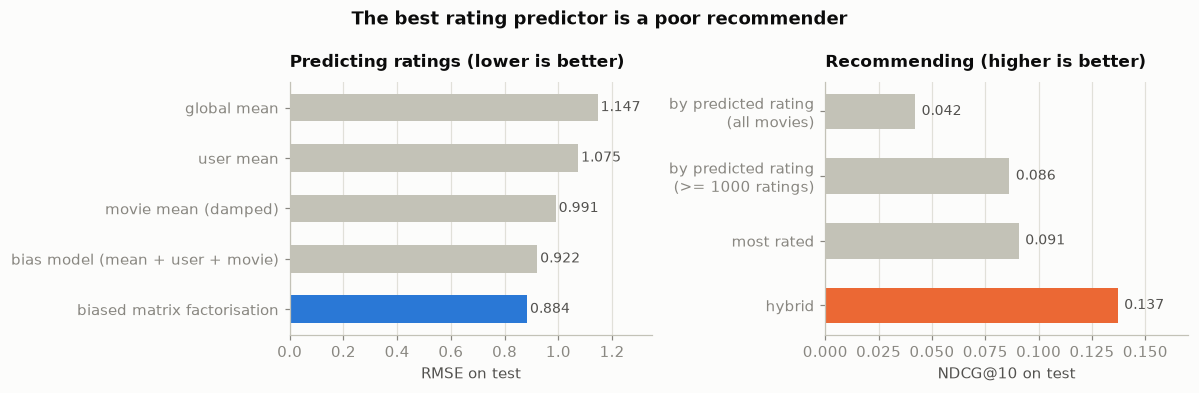

In [77]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
r_ = rating_table["test RMSE"]
y1 = np.arange(len(r_))[::-1]
a1.barh(y1, r_.values, height=0.55, color=[GRAY] * (len(r_) - 1) + [BLUE])
for y_, v in zip(y1, r_.values):
    a1.text(v + 0.01, y_, f"{v:.3f}", va="center", color=INK2, fontsize=9)
a1.set_yticks(y1, r_.index); a1.set(title="Predicting ratings (lower is better)", xlabel="RMSE on test", xlim=(0, 1.35))
only_grid(a1, "x")
c_ = cmp["ndcg@10"]
labels = ["by predicted rating\n(all movies)", "by predicted rating\n(>= 1000 ratings)", "most rated", "hybrid"]
y2 = np.arange(len(c_))[::-1]
a2.barh(y2, c_.values, height=0.55, color=[GRAY, GRAY, GRAY, ORANGE])
for y_, v in zip(y2, c_.values):
    a2.text(v + 0.003, y_, f"{v:.3f}", va="center", color=INK2, fontsize=9)
a2.set_yticks(y2, labels); a2.set(title="Recommending (higher is better)", xlabel="NDCG@10 on test", xlim=(0, 0.17))
only_grid(a2, "x")
fig.suptitle("The best rating predictor is a poor recommender", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

Rating prediction improves steadily with model complexity: from 1.147 (global mean) down to 0.884 for biased matrix factorisation, and most of that gain comes from modelling user and movie biases. But a lower RMSE did not give a better recommender. Ranking movies by predicted stars gives NDCG@10 of 0.042, less than half of the plain “most rated” list (0.091). Predicted stars reward movies a few enthusiasts rated highly, while the test only counts movies the user actually went on to watch and like. Restricting to movies with at least 1,000 ratings recovers 0.086, but coverage collapses to 3.3%, so the list becomes a popularity list again. RMSE answers “how many stars would this user give?”; a recommender must answer “which ten movies should this user watch next?”. That is why the headline metric in this project is NDCG@10 and RMSE stays a secondary diagnostic.


## Conclusion, limitations and next steps
**Result.** A hybrid of item-kNN and implicit ALS reaches NDCG@10 of 0.137 on a held-out test set, against 0.091 for "most rated" and 0.099 for demographic popularity. It comes with a faithful reason for every recommendation, a tested cold-start policy and a demo app. Lower RMSE did not mean better recommendations.

**Limitations.** One dataset from 2000–2003, with a heavy month in November 2000. Offline metrics treat unrated movies as misses. The split is chronological per user, not global. Only about 19% of the catalogue is ever recommended. The popularity penalty costs accuracy. Explanations describe the item-kNN part of the model, not the ALS part. There is no online test.

**Next steps.** Add TMDB descriptions and cast to improve new-movie content features; test on a newer dataset; try a sequence-aware model; add an online A/B test; generate the explanations with a language model.

**Reproducing.** The notebook needs about 6–8 GB of RAM and must be run top to bottom.